# Predicting Restaurant Inspection Grades in New York City

### Will a restaurant earn a Grade A - or slip to a Grade B or C?

**CS 667 Practical Data Science - Fall 2026 - Midterm Project**

**Team:** Rafiul Haider & Shadman Rahman
**Instructor:** Dr. Krishna Bathula, Pace University
**Due:** October 27, 2026

---

## The project in one line

Using the **DOHMH New York City Restaurant Inspection Results** dataset - raw, violation-level data from **NYC Open Data** (also listed on Data.gov) - we explore how inspection scores and grades vary across the five boroughs, cuisine types, and inspection types, and we set up a **binary classification** problem: predict whether an inspection will end in a **Grade A (0)** or a **Grade B / C (1)**, using only information known *before* the inspection takes place.

## Why it matters

- **For the Health Department:** spot the inspections most likely to go badly, and prioritize visits and follow-up where the risk is highest.
- **For restaurant operators:** see the risk patterns - borough, cuisine, inspection type, past history - and fix problems *before* the inspector arrives.

## How this notebook is organized

1. **Setup** - load the libraries
2. **Load the raw data** - one row per violation, straight from NYC Open Data
3. **First look** - shape, columns, data types, sample rows
4. **Clean and aggregate** - one record per inspection
5. **Exploratory analysis** - score and grade distribution, missing values, outliers, violation patterns, borough / cuisine / inspection-type differences, correlation heat map
6. **Preprocessing** - missing values, categorical encoding, scaling, and building the prior-history features
7. **The classification problem** - Grade A vs. Grade B / C, defined carefully so nothing from the inspection itself leaks into the predictors
8. **The map** - where inspections happen, where they go badly, ZIP and neighborhood risk, and the 3D views (Section 13 below)
9. **Prediction** - will this inspection end in a B or C? History features, a time-based split, and four models compared honestly (Section 14 below)


## 1. Setup

This cell loads the Python libraries the rest of the notebook depends on: pandas and numpy for the data work, matplotlib and seaborn for the charts. It also sets a few display options, like how many columns pandas prints, so wide tables do not get cut off, and it fixes one plot style for the whole notebook so the charts match each other. Nothing analytical happens here. It exists so anyone who opens the notebook, including us in two weeks, can run the cells from the top and get the same starting point.


In [98]:
# pandas does the table work, numpy handles the number side of things
import pandas as pd
import numpy as np

# matplotlib is the plotting base, seaborn builds nicer charts on top
import matplotlib.pyplot as plt
import seaborn as sns

# show all the columns when a dataframe prints, or the wide tables get cut off
pd.set_option("display.max_columns", 50)
# wider printouts so rows do not wrap in the middle of a value
pd.set_option("display.width", 120)

# one plot style for the whole notebook so the charts match each other
plt.style.use("ggplot")
sns.set_palette("Set2")

print("Libraries loaded.")
print("pandas:", pd.__version__, "| numpy:", np.__version__)


Libraries loaded.
pandas: 2.2.3 | numpy: 2.1.3


## 2. Load the raw data

Here we read the CSV exactly as NYC Open Data serves it and put it in a dataframe called `df_raw`. The important thing to notice is the grain of the data: one row is one violation, so a single inspection of a single restaurant usually takes up several rows, with the score and grade repeated on each one. We keep this raw version untouched, because every cleaning decision comes later and we want to be able to redo them without downloading the file again. In the run we did while writing this, the file had **295,356 rows and 27 columns** (the city updates it daily, so the count moves a little).


In [99]:
# the direct download link for the dataset on NYC Open Data.
# rows.csv always gives the current full file.
DATA_URL = "https://data.cityofnewyork.us/api/views/43nn-pn8j/rows.csv?accessType=DOWNLOAD"

# Important: this file is RAW data, exactly as the city publishes it.
# There is one row per VIOLATION, not one row per inspection.
# A single inspection with 6 violations takes up 6 rows, and score and
# grade repeat on every one of those rows. We deal with that in Cell 5.
# low_memory=False stops pandas from guessing column types in chunks,
# which gave us mixed-type warnings on the ZIPCODE and PHONE columns.
df_raw = pd.read_csv(DATA_URL, low_memory=False)

print("Raw file loaded.")
print("Shape (rows, columns):", df_raw.shape)


Raw file loaded.
Shape (rows, columns): (295356, 27)


## 3. First look at the data

We print the first few rows, the column names and data types, and a summary of every column. Most of the file arrives as text, including the dates, and even SCORE comes in as text at first, so this pass tells us what needs converting before anything else can happen. It is also where odd things first show up, like placeholder dates or columns that are mostly empty. We would rather find those here than halfway through a chart.


In [100]:
# the first few rows, just to see what a record actually looks like
df_raw.head()

# what each column is called and what type pandas gave it.
# Almost everything comes in as text (object), even SCORE at first.
df_raw.dtypes

# one list of every column name, easier to read than the dtypes output
list(df_raw.columns)

# quick summary of every column: counts, how many unique values,
# the most common value, plus mean/min/max where the column is numeric
df_raw.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CAMIS,295356.0,NaN,NaN,NaN,48254202.104579,3630675.08157,30075445.0,50013843.0,50103586.0,50139003.0,50193978.0
DBA,295353,24634,DUNKIN,3104,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BORO,295356,6,Manhattan,109304,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BUILDING,294349,8558,1,1508,NaN,NaN,NaN,NaN,NaN,NaN,NaN
STREET,295301,2229,BROADWAY,11404,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ZIPCODE,292187.0,NaN,NaN,NaN,10707.139291,617.796418,6605.0,10023.0,11101.0,11233.0,69361.0
PHONE,295246,27757,7182246030,195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CUISINE DESCRIPTION,291362,90,American,43897,NaN,NaN,NaN,NaN,NaN,NaN,NaN
INSPECTION DATE,295356,1956,01/01/1900,3914,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ACTION,291442,5,Violations were cited in the following area(s).,274490,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Cleaning the basics, then one record per inspection

This is the most involved step in the project. First we tidy up: column names become lowercase with underscores, the date columns become real dates, and SCORE becomes a number. One quirk to know about: the city uses 01/01/1900 as a placeholder date for restaurants that are in the system but have never been inspected. There were **3,914 of those rows (about 1.3%)** in our run, and they have no score and no grade.

Then we group the violation rows into inspections. Our grouping key is restaurant (CAMIS) + inspection date + inspection type. The type has to be part of the key: 8,456 restaurant-days in this file carry more than one inspection type on the same date, and without the type those separate visits would merge into one fake inspection. Inside a group the score and grade are the same on every row (we checked), so we take them once, and we count the violations and the critical violations, since those counts are real information about the visit. The result, `df_insp`, has **96,897 inspections from 31,443 restaurants**. Every comparison after this point would be misleading without this step, because a restaurant with nine violations in one visit would otherwise count nine times as much as a restaurant with one.


In [101]:
# work on a copy so the raw frame stays untouched if we mess up
df = df_raw.copy()

# column names arrive in ALL CAPS with spaces, like "CUISINE DESCRIPTION".
# Lowercase with underscores is easier to type and harder to get wrong.
df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]
print("New column names:")
print(list(df.columns))

# the date columns are text like "01/15/2025". Turn them into real dates
# so we can sort, filter, and pull out year and month later.
# errors="coerce" turns anything unparseable into NaT instead of crashing.
df["inspection_date"] = pd.to_datetime(df["inspection_date"], errors="coerce")
df["grade_date"] = pd.to_datetime(df["grade_date"], errors="coerce")

# SCORE is stored as text in the raw file. Make it a number.
# Blank scores (restaurants not graded yet) become NaN.
df["score"] = pd.to_numeric(df["score"], errors="coerce")

# The city uses 01/01/1900 as a placeholder date for restaurants that
# are in the system but have never been inspected. Those rows have no
# score and no grade. We count them here so we can talk about them
# instead of quietly letting them skew anything date-based later.
n_placeholder = (df["inspection_date"] == pd.Timestamp("1900-01-01")).sum()
print("Rows with the 1900-01-01 placeholder date (never inspected):", n_placeholder)
print("Share of all rows: {:.1f}%".format(100 * n_placeholder / len(df)))

# peek at the date range of the real inspections only
real_dates = df.loc[df["inspection_date"] > pd.Timestamp("1900-01-01"), "inspection_date"]
print("Earliest real inspection date:", real_dates.min())
print("Latest real inspection date:  ", real_dates.max())


New column names:
['camis', 'dba', 'boro', 'building', 'street', 'zipcode', 'phone', 'cuisine_description', 'inspection_date', 'action', 'violation_code', 'violation_description', 'critical_flag', 'score', 'grade', 'grade_date', 'record_date', 'inspection_type', 'latitude', 'longitude', 'community_board', 'council_district', 'census_tract', 'bin', 'bbl', 'nta', 'location']
Rows with the 1900-01-01 placeholder date (never inspected): 3914
Share of all rows: 1.3%
Earliest real inspection date: 2007-08-10 00:00:00
Latest real inspection date:   2026-10-19 00:00:00


In [102]:
# Sanity checks we ran before grouping (one-off checks, not saved as
# cells): inside a camis + inspection_date + inspection_type group, the
# score never varied (no group had 2 different scores) and neither did
# the grade. So taking "max" or "first" inside a group gives the same
# answer, and the group really is one inspection.
# Leaving inspection_type out of the key was worse: 8,456 restaurant-days
# have more than one inspection type on the same date (a cycle inspection
# plus a separate limited visit, for example), and those would have been
# merged into one fake inspection.

# helper column: 1 when the violation was flagged Critical, else 0.
# Summing this inside a group counts the critical violations.
df["is_critical"] = (df["critical_flag"].str.strip() == "Critical").astype(int)

rows_before = len(df)

# The grouping key we settled on: camis + inspection_date + inspection_type.
# camis alone is the restaurant, and one restaurant can be inspected
# twice on the same day under different inspection types, so the type
# has to be part of the key or two separate visits would get merged.
insp = (
    df.groupby(["camis", "inspection_date", "inspection_type"], dropna=False)
    .agg(
        dba=("dba", "first"),                          # restaurant name
        boro=("boro", "first"),                        # borough
        cuisine_description=("cuisine_description", "first"),
        zipcode=("zipcode", "first"),
        score=("score", "max"),                        # same value on all rows in the group
        grade=("grade", "first"),                      # "first" skips blanks, takes the real grade
        grade_date=("grade_date", "first"),
        latitude=("latitude", "first"),
        longitude=("longitude", "first"),
        n_violations=("camis", "size"),                # rows in the group. Note: an inspection
                                                       # where nothing was cited still gets one
                                                       # row, with a blank violation code
        n_critical=("is_critical", "sum"),             # how many of them were critical
    )
    .reset_index()
)

df_insp = insp

print("Rows before aggregating (one row per violation): ", rows_before)
print("Rows after aggregating  (one row per inspection):", len(df_insp))
print("Unique restaurants (camis) in the data:", df_insp["camis"].nunique())
df_insp.head()


Rows before aggregating (one row per violation):  295356
Rows after aggregating  (one row per inspection): 96897
Unique restaurants (camis) in the data: 31443


,camis,inspection_date,inspection_type,dba,boro,cuisine_description,zipcode,score,grade,grade_date,latitude,longitude,n_violations,n_critical
0,30075445,2023-08-01,Cycle Inspection / Initial Inspection,MORRIS PARK BAKE SHOP,Bronx,Bakery Products/Desserts,10462.0,38.0,None,NaT,40.848231,-73.855972,3,2
1,30075445,2023-08-22,Cycle Inspection / Re-inspection,MORRIS PARK BAKE SHOP,Bronx,Bakery Products/Desserts,10462.0,12.0,A,2023-08-22,40.848231,-73.855972,3,1
2,30075445,2024-11-08,Cycle Inspection / Initial Inspection,MORRIS PARK BAKE SHOP,Bronx,Bakery Products/Desserts,10462.0,10.0,A,2024-11-08,40.848231,-73.855972,3,1
3,30075445,2026-02-27,Cycle Inspection / Initial Inspection,MORRIS PARK BAKE SHOP,Bronx,Bakery Products/Desserts,10462.0,7.0,A,2026-02-27,40.848231,-73.855972,2,1
4,30191841,2024-11-20,Cycle Inspection / Initial Inspection,D.J. REYNOLDS,Manhattan,Irish,10019.0,24.0,None,NaT,40.767326,-73.984310,6,2


## 5. Score distribution and outliers

Now we can describe the outcome we care about. The city's scale runs backwards from what most people expect: points are added for violations, so a low score is good. Grade A is 0 to 13 points, B is 14 to 27, and C is 28 or more. The histogram below shows how inspection scores spread across those bands, with the two grade cutoffs marked.

The same cell looks for outliers with the interquartile range rule. Of the 82,619 inspections that have a score, the median is 13 and the mean is 17.9. Anything above the upper fence of 46.5 counts as an outlier, and there were **4,095 of those (about 5%)**, with the worst score in the data at 214. We keep genuine extreme inspections in the data. A 90 point visit is a real event the Health Department cares about, and we only remove values we can show are wrong.


count    82619.000000
mean        17.869195
std         14.924264
min          0.000000
25%          9.000000
50%         13.000000
75%         24.000000
max        214.000000
Name: score, dtype: float64
Q1: 9.0 | Q3: 24.0 | IQR: 15.0
Upper fence: 46.5
Inspections scoring above the fence: 4095 (5.0% of graded inspections)
Worst (highest) score in the data: 214.0


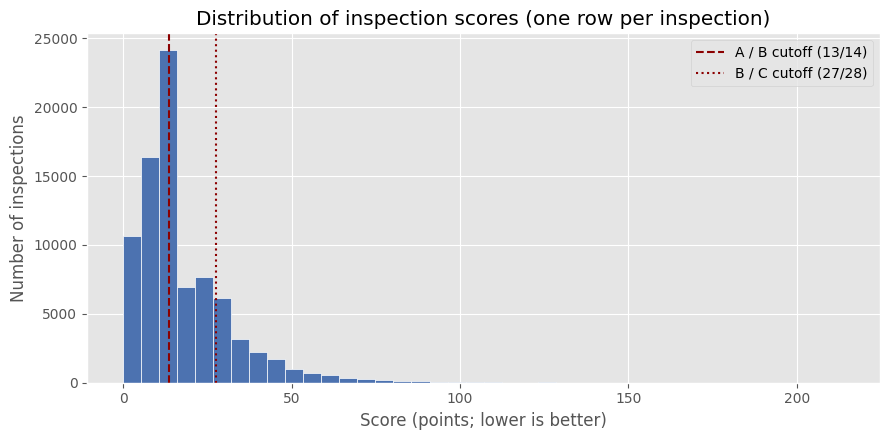

In [103]:
# how the inspection scores spread out. Reminder on how scoring works
# here: points are added for violations, so a LOW score is good.
# Grade A is 0 to 13 points, B is 14 to 27, C is 28 or more.
score = df_insp["score"].dropna()
print(score.describe())

# quartiles and the IQR rule for outliers: anything above
# Q3 + 1.5 * IQR counts as an outlier on the high (bad) side
q1, q3 = score.quantile(0.25), score.quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
n_outliers = (score > upper_fence).sum()
print("Q1:", q1, "| Q3:", q3, "| IQR:", iqr)
print("Upper fence:", upper_fence)
print("Inspections scoring above the fence:", n_outliers,
      "({:.1f}% of graded inspections)".format(100 * n_outliers / len(score)))
print("Worst (highest) score in the data:", score.max())

plt.figure(figsize=(9, 4.5))
plt.hist(score, bins=40, color="#4C72B0", edgecolor="white")
plt.axvline(13.5, color="darkred", linestyle="--", label="A / B cutoff (13/14)")
plt.axvline(27.5, color="darkred", linestyle=":", label="B / C cutoff (27/28)")
plt.title("Distribution of inspection scores (one row per inspection)")
plt.xlabel("Score (points; lower is better)")
plt.ylabel("Number of inspections")
plt.legend()
plt.tight_layout()
plt.show()


## 6. Grade distribution

Same outcome, counted by letter instead of by points. This is the table the prediction problem later depends on, because it shows how common a B or C actually is. In our run: **A 44,503 (45.9%), B 4,276, C 2,221**, and 41,882 inspections (43.2%) with no grade recorded yet, plus small numbers of N, Z and P grades. So among inspections that received an A, B or C, a B or C is the less common outcome, roughly one in eight. Worth remembering when we judge a model later: guessing A every time would already look right most of the time, which is exactly why accuracy alone will not be enough.


       inspections  percent
grade                      
A            44503     45.9
None         41882     43.2
B             4276      4.4
C             2221      2.3
N             2218      2.3
Z             1266      1.3
P              531      0.5


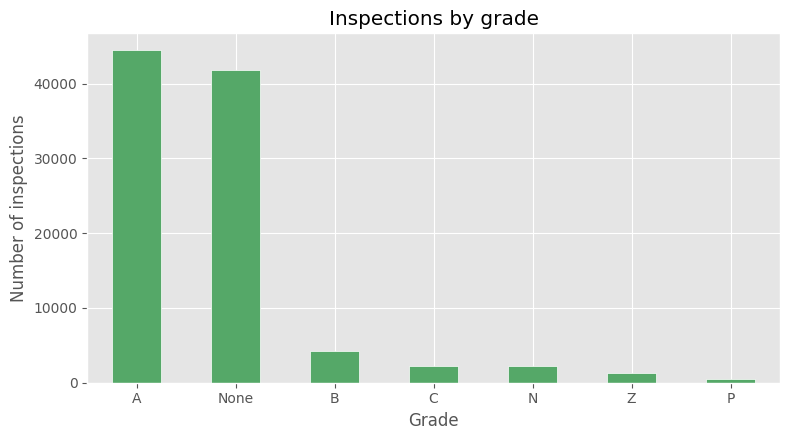

In [104]:
# count of each grade, with the share next to it.
# Grades other than A, B, C exist (N = not yet graded, Z, P), and some
# inspections have no grade at all, so we keep dropna=False and say so.
grade_counts = df_insp["grade"].value_counts(dropna=False)
grade_pct = df_insp["grade"].value_counts(normalize=True, dropna=False) * 100

grade_table = pd.DataFrame({"inspections": grade_counts, "percent": grade_pct.round(1)})
print(grade_table)

plt.figure(figsize=(8, 4.5))
grade_counts.plot(kind="bar", color="#55A868", edgecolor="white")
plt.title("Inspections by grade")
plt.xlabel("Grade")
plt.ylabel("Number of inspections")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 7. Missing values

We count the missing entries in every column of the inspection-level table and show them as percentages. Some gaps have ordinary explanations. Grade date is missing for 45.5% of inspections and grade for 43.2%, mostly because those inspections have not been graded yet or were not the kind of visit that ends in a grade. Score is missing for 14.7%, and cuisine for 4.1%. The point of listing them all is to decide, column by column, whether a gap is safe to drop, worth filling in, or a sign that the column should not be used at all. Those decisions happen in the preprocessing section.


                     n_missing  percent_missing
grade_date               44094            45.51
grade                    41882            43.22
score                    14278            14.74
cuisine_description       3932             4.06
inspection_type           3914             4.04
zipcode                   1182             1.22
latitude                   764             0.79
longitude                  764             0.79
camis                        0             0.00
inspection_date              0             0.00
boro                         0             0.00
dba                          3             0.00
n_violations                 0             0.00
n_critical                   0             0.00


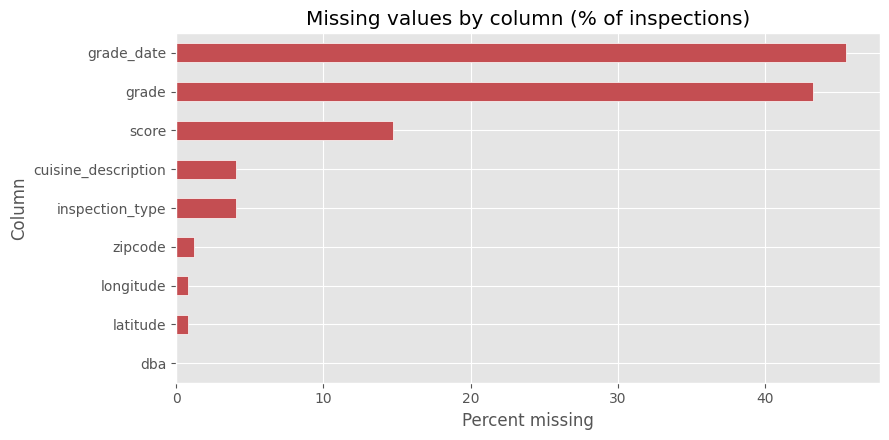

In [105]:
# for each column: how many values are missing, and what percent that is.
# Sorted worst first, because those are the columns we have to think about.
missing = (
    df_insp.isna()
    .sum()
    .rename("n_missing")
    .to_frame()
    .assign(percent_missing=lambda t: (100 * t["n_missing"] / len(df_insp)).round(2))
    .sort_values("percent_missing", ascending=False)
)
print(missing)

# chart only the columns that actually have missing values
has_missing = missing[missing["n_missing"] > 0]
plt.figure(figsize=(9, 4.5))
has_missing["percent_missing"].sort_values().plot(kind="barh", color="#C44E52", edgecolor="white")
plt.title("Missing values by column (% of inspections)")
plt.xlabel("Percent missing")
plt.ylabel("Column")
plt.tight_layout()
plt.show()


## 8. Violation patterns

Each violation in the raw file has a code and a short description, plus a flag for whether it was critical. This section goes back to the violation level and counts which codes appear most often. It answers a practical question: when restaurants lose points, what are they usually losing them for, and how much of it is critical items like food temperature and vermin, compared with facility and paperwork problems. For a restaurant operator, this is probably the most directly useful chart in the notebook, because these are the specific things that can be checked and fixed before an inspection.


Top 10 violation codes:
violation_code
10F    41137
08A    25162
06C    19004
10B    18943
02G    18911
06D    18505
02B    15415
04L    13844
04N    11383
04A     7721
Name: count, dtype: int64
                                                      description  times_cited  share_critical
violation_code                                                                                
10F             Non-food contact surface or equipment made of ...        41137             0.0
08A             Establishment is not free of harborage or cond...        25162             0.0
06C             Food, supplies, or equipment not protected fro...        19004           100.0
10B             Anti-siphonage or back-flow prevention device ...        18943             0.0
02G             Cold TCS food item held above 41 °F; smoked or...        18911           100.0
06D             Food contact surface not properly washed, rins...        18505           100.0
02B                Hot TCS food item not held

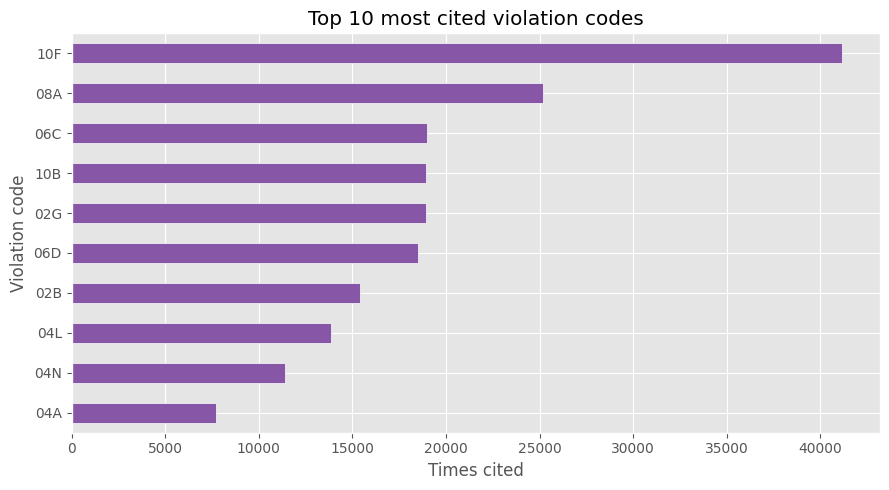

In [106]:
# Violation patterns: what do restaurants actually get cited for?
# This one works at the violation level, so we use df (the cleaned raw
# frame), not df_insp. Rows for never-inspected restaurants have no
# violation code, so drop blanks first.
viol = df[df["violation_code"].notna() & (df["violation_code"].astype(str).str.strip() != "")].copy()

top_codes = viol["violation_code"].value_counts().head(10)
print("Top 10 violation codes:")
print(top_codes)

# the plain-English description for each of those codes, and how often
# each one was flagged critical
desc = (
    viol[viol["violation_code"].isin(top_codes.index)]
    .groupby("violation_code")
    .agg(
        description=("violation_description", "first"),
        times_cited=("violation_code", "size"),
        share_critical=("is_critical", "mean"),
    )
    .reindex(top_codes.index)
    .assign(share_critical=lambda t: (100 * t["share_critical"]).round(1))
)
print(desc)

plt.figure(figsize=(9, 5))
top_codes.sort_values().plot(kind="barh", color="#8856A7", edgecolor="white")
plt.title("Top 10 most cited violation codes")
plt.xlabel("Times cited")
plt.ylabel("Violation code")
plt.tight_layout()
plt.show()


## 9. Comparisons by borough, cuisine and inspection type

We group the inspection-level data and compare scores across groups. By borough first: the medians are close (Manhattan 12, the other four boroughs 13), while Queens has the highest mean at 19.2, which says Queens has a longer tail of bad inspections rather than worse typical ones. One odd detail: 84 inspections have the borough recorded as "0", which is the file's way of saying it was not recorded. We left them in rather than quietly deleting data.

Then the grade mix inside each borough, as row percentages, so boroughs of very different sizes can still be compared. After that, cuisine: we limit the chart to the 15 cuisines with the most inspections, since some cuisine labels cover only a few dozen restaurants and their averages would not mean much. American is the most inspected cuisine (14,944 inspections). Among the top 15, Latin American has the highest median score (16) and Donuts and Hamburgers the lowest (10).

A caution that belongs with inspection type, which we compare in the preprocessing work: a re-inspection usually happens because the first visit went poorly, so that group starts from a worse position, and initial inspections and re-inspections are not directly comparable.


               count  median   mean    std
boro                                      
0                 84    12.0  16.74  14.23
Manhattan      31230    12.0  17.14  14.62
Bronx           7760    13.0  17.58  13.74
Brooklyn       21289    13.0  17.94  15.58
Queens         19367    13.0  19.23  15.34
Staten Island   2889    13.0  16.94  12.73


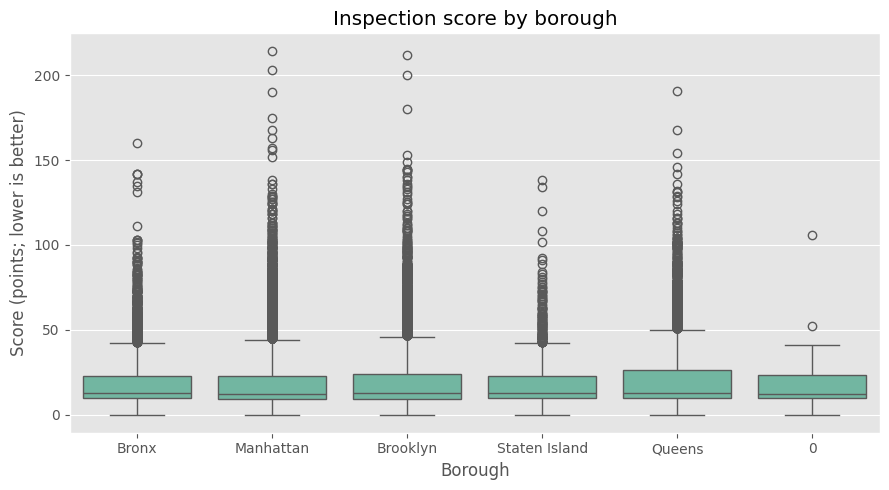

In [107]:
# median is the fair comparison here. The mean gets pulled up by the
# small number of very bad inspections we saw in the outlier count.
# One odd row to know about: 84 inspections have boro recorded as "0".
# That is the file's way of saying the borough was not recorded. We left
# them in rather than quietly deleting data.
boro_score = (
    df_insp.groupby("boro")["score"]
    .agg(["count", "median", "mean", "std"])
    .round(2)
    .sort_values("median")
)
print(boro_score)

plt.figure(figsize=(9, 5))
sns.boxplot(data=df_insp, x="boro", y="score")
plt.title("Inspection score by borough")
plt.xlabel("Borough")
plt.ylabel("Score (points; lower is better)")
plt.tight_layout()
plt.show()


grade             A    B    C    N    P    Z
boro                                        
0              85.0  6.7  5.0  1.7  1.7  0.0
Bronx          80.6  9.6  4.1  3.1  0.7  1.9
Brooklyn       80.9  7.4  4.0  4.2  1.2  2.3
Manhattan      82.5  6.7  3.5  4.4  0.8  2.1
Queens         78.2  9.2  5.2  3.4  1.1  2.9
Staten Island  81.5  8.2  2.7  5.7  0.5  1.5


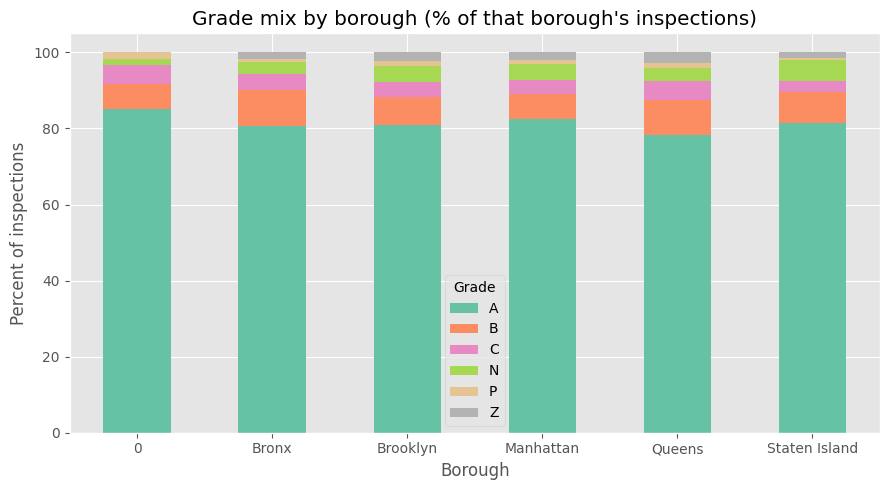

In [108]:
# same grades as Cell 7, but the share inside each borough.
# Row percentages, so each borough adds up to 100 and we compare the
# shape of the mix rather than borough sizes.
grade_mix = pd.crosstab(df_insp["boro"], df_insp["grade"], normalize="index") * 100
print(grade_mix.round(1))

grade_mix.plot(kind="bar", stacked=True, figsize=(9, 5), colormap="Set2")
plt.title("Grade mix by borough (% of that borough's inspections)")
plt.xlabel("Borough")
plt.ylabel("Percent of inspections")
plt.legend(title="Grade")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


                                inspections  median_score
cuisine_description                                      
American                              14944          12.0
Chinese                                7950          15.0
Coffee/Tea                             7913          12.0
Pizza                                  5595          13.0
Latin American                         4314          16.0
Bakery Products/Desserts               3778          12.0
Mexican                                3698          13.0
Japanese                               3190          13.0
Caribbean                              3064          15.0
Italian                                2979          13.0
Chicken                                2625          12.0
Donuts                                 2126          10.0
Juice, Smoothies, Fruit Salads         2004          12.0
Sandwiches                             1796          12.0
Hamburgers                             1778          10.0


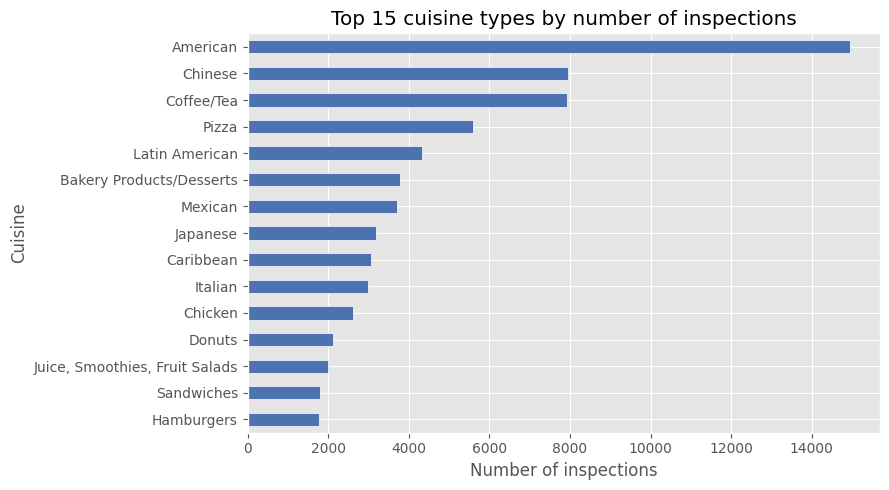

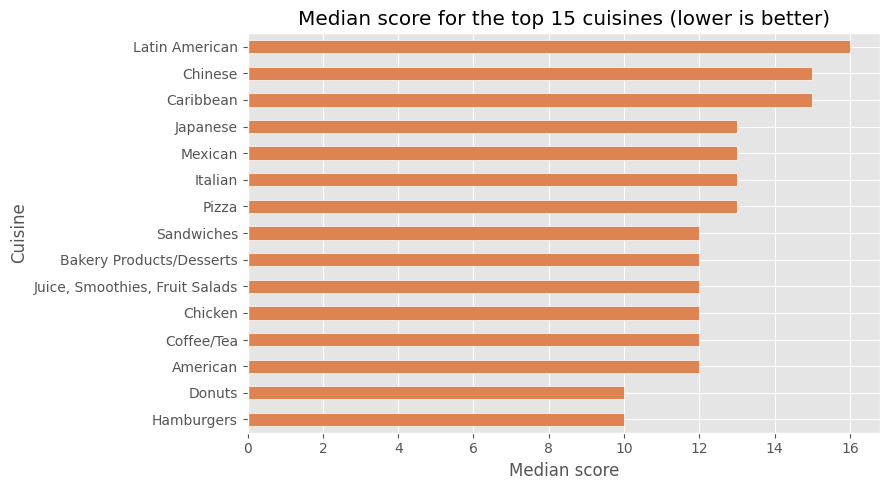

In [109]:
# the raw file has a lot of cuisine labels, including some very small
# ones. The top 15 by inspection count are the ones worth discussing.
cuisine_stats = (
    df_insp.groupby("cuisine_description")
    .agg(inspections=("score", "size"), median_score=("score", "median"))
    .sort_values("inspections", ascending=False)
    .head(15)
)
print(cuisine_stats)

plt.figure(figsize=(9, 5))
cuisine_stats["inspections"].sort_values().plot(kind="barh", color="#4C72B0", edgecolor="white")
plt.title("Top 15 cuisine types by number of inspections")
plt.xlabel("Number of inspections")
plt.ylabel("Cuisine")
plt.tight_layout()
plt.show()

# same 15 cuisines, now sorted by median score so we can see whether
# the busiest cuisines also score worse or better than the rest
plt.figure(figsize=(9, 5))
cuisine_stats["median_score"].sort_values().plot(kind="barh", color="#DD8452", edgecolor="white")
plt.title("Median score for the top 15 cuisines (lower is better)")
plt.xlabel("Median score")
plt.ylabel("Cuisine")
plt.tight_layout()
plt.show()


## 10. Inspections over time

Monthly and yearly counts of inspections, after removing the 1900 placeholder rows (one fake month in the year 1900 would flatten the whole chart). Read the left edge of this chart with care: the file is a rolling window, so almost everything in it is from 2022 onward and the counts thin out fast before that. The thin left edge is missing history, not a quiet period for inspections.


Inspections per year:
inspection_date
2007       12
2008        6
2009        1
2010        4
2011        2
2012        5
2013        1
2014        5
2015        9
2016       89
2017      168
2018      237
2019      250
2020       59
2021       78
2022     2438
2023    13107
2024    24445
2025    27169
2026    24898
Name: count, dtype: int64


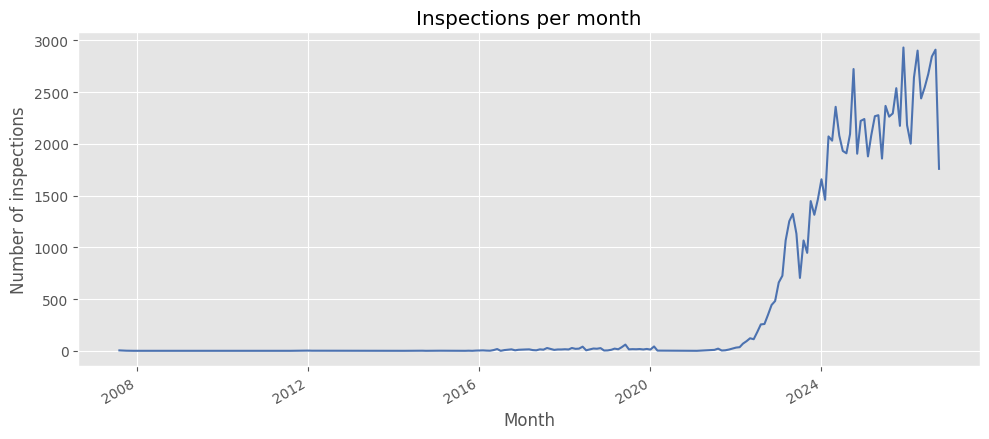

In [110]:
# monthly counts. We filter out the 1900 placeholder rows first, or one
# fake month in the year 1900 flattens the whole chart.
dated = df_insp[df_insp["inspection_date"] > pd.Timestamp("1900-01-01")].copy()

# count per month by grouping on the year-month period of each date.
# The index comes back as text labels so we can plot it directly.
monthly = dated.groupby(dated["inspection_date"].dt.to_period("M")).size()
monthly.index = monthly.index.to_timestamp()
yearly = dated["inspection_date"].dt.year.value_counts().sort_index()

print("Inspections per year:")
print(yearly)

plt.figure(figsize=(10, 4.5))
monthly.plot(color="#4C72B0")
plt.title("Inspections per month")
plt.xlabel("Month")
plt.ylabel("Number of inspections")
plt.tight_layout()
plt.show()
# Read the yearly counts before trusting the left edge of this chart:
# the file is a rolling window, so almost everything in it is from the
# last few years and the counts thin out fast before 2022. That thin
# left edge is missing history, not a quiet period for inspections.


## 11. Correlation heat map

We take the numeric columns at the inspection level (score, number of violations, number of critical violations, latitude, longitude), compute the correlation between each pair, and draw it as a colored grid. Strong colors mean two columns tend to move together. Two of these relationships need a comment. Score and critical violations correlate at 0.86, and score and violation count at 0.85, but that is partly mechanical: the score is built out of violation points, so of course they move together. And latitude and longitude correlate at almost exactly -1, which is geography, not restaurants: the city runs from southwest to northeast, so as one goes up the other tends to come down. The correlations worth paying attention to, later, are the ones between the outcome and the fields we would actually know in advance.


              score  n_violations  n_critical  latitude  longitude
score          1.00          0.85        0.86      0.02      -0.02
n_violations   0.85          1.00        0.89      0.02      -0.01
n_critical     0.86          0.89        1.00      0.02      -0.02
latitude       0.02          0.02        0.02      1.00      -1.00
longitude     -0.02         -0.01       -0.02     -1.00       1.00


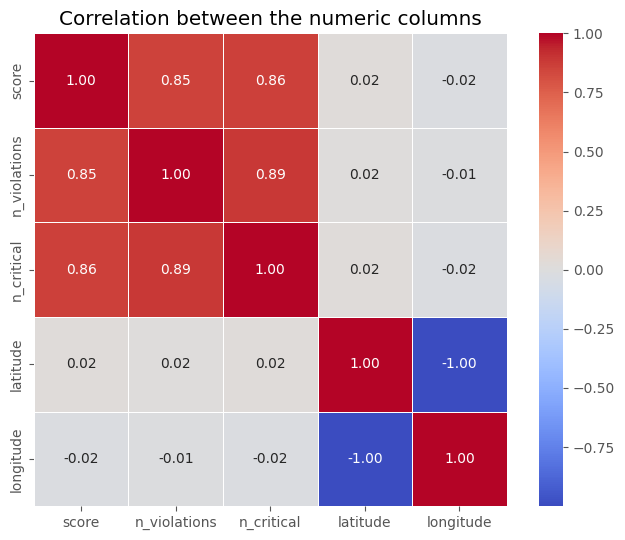

In [111]:
# correlations only make sense on numbers, so pick the numeric columns.
# Read this carefully: score and n_critical moving together does NOT
# mean critical violations cause the score on their own. The score is
# built from violation points, so some of this is mechanical.
# The near-perfect -1.00 between latitude and longitude is real too:
# the city runs southwest to northeast, so as one goes up the other
# comes down. It tells us about the map, not about restaurants.
numeric_cols = ["score", "n_violations", "n_critical", "latitude", "longitude"]
corr = df_insp[numeric_cols].corr(numeric_only=True)
print(corr.round(2))

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5)
plt.title("Correlation between the numeric columns")
plt.tight_layout()
plt.show()


## 12. Checkpoint: save the inspection-level table

Everything after this point (deeper EDA, the history features, and the classification target) starts from one row per inspection, so we save that table now. Next session we can load this file instead of redoing the download and the aggregation. One practical note for Colab: files saved in a session disappear when the runtime shuts down, so download a copy of the CSV as well.

## What comes next

Two sections follow this base EDA in the full project. Preprocessing (missing values decided column by column, cuisine labels that are too rare grouped into an "Other" category, borough and inspection type turned into one-hot columns, numeric fields scaled) and the history features: for each restaurant, inspections sorted by date, with the previous score, the days since the previous inspection, and the count of earlier inspections recorded for each visit. Each history value is shifted by one inspection, so a visit is only ever described using visits that already happened.

Then the classification problem itself. The target is 1 when the grade is B or C and 0 when it is A, using only graded inspections. The features are restricted to what is known before the inspection starts: borough, cuisine type, inspection type, and the history features. The score, grade and violations from the inspection being predicted stay out, because using them would amount to answering the question with its own answer. We will split by time, training on earlier inspections and testing on later ones, since that matches how the tool would be used in practice, and a simple logistic regression will be the first model and the baseline everything else is compared against.


In [112]:
# Everything after this point (deeper EDA, features, and later the
# classification target) starts from one row per inspection, so we
# save that table now. Next session we load this file instead of
# redoing the download and the aggregation.
# In Colab this lands in the session's file area; download a copy,
# because Colab files disappear when the runtime shuts down.
df_insp.to_csv("inspections_one_row_per_inspection.csv", index=False)
print("Saved:", len(df_insp), "rows to inspections_one_row_per_inspection.csv")


Saved: 96897 rows to inspections_one_row_per_inspection.csv


## 13. The map: where inspections happen, and where they go badly

*What this part means:* every chart so far treats the city as one pool of
inspections. This section puts the inspections on the map and asks the
"where" questions: where is the inspection workload, where do inspections
end badly, and is a bad area really about the place or about the kind of
visit? Three ground rules run through the whole section. We map rates,
not raw counts, because counts mostly redraw where restaurants are. A
region only earns a rate when at least 30 of its inspections have a
grade; below that the number swings on a handful of visits, so the region
shows in grey instead. And in the 3D views, height is always the number of
inspections (workload) and color is always how the inspections turned
out. Height never carries the score.

*The regions:* boroughs are too coarse (five areas, and Section 9 already
showed their median scores are nearly the same). ZIP codes are the
working region: small enough to mean something, big enough to hold a
rate, and the file already carries them. One map uses the city's own
neighborhood areas (NTAs), which have real names instead of numbers.


### 13.1 Map prep: cleaning the coordinates

*What this part means:* before anything is mapped, the coordinates get
audited. Some rows in this file sit at latitude and longitude 0, which is
in the ocean off West Africa, and some have no coordinates at all. The
cell below drops those and anything outside the city box, prints how
many inspections survive, and turns the ZIP column into clean 5-digit
text so it can join to boundary files later. On the current file, 95,010
of 96,897 inspections have a usable location.


In [113]:
# A map is only as honest as its point cleaning. We drop inspections with
# missing coordinates, coordinates stored as 0, and anything outside the
# city box. Every count below gets printed so the drop is on the record.

import json
import urllib.request

import numpy as np
import pandas as pd

CSV_PATH = "inspections_one_row_per_inspection.csv"
NYC_CENTER = {"lat": 40.73, "lon": -73.93}  # rough middle of the five boroughs

try:
    # the base EDA already built df_insp, so reuse it when it is there
    map_src = df_insp.copy()
    print("Using df_insp from the earlier sections:", map_src.shape)
except NameError:
    map_src = pd.read_csv(CSV_PATH)
    print("Loaded checkpoint CSV:", map_src.shape)

# ZIP codes arrive as floats like 10462.0. Turn them into 5 character
# strings so they can join to the boundary file in M4.
zip_num = pd.to_numeric(map_src["zipcode"], errors="coerce")
map_src["zip5"] = zip_num.map(lambda v: f"{int(v):05d}" if pd.notna(v) else np.nan)

map_src["inspection_date"] = pd.to_datetime(map_src["inspection_date"], errors="coerce")

n_start = len(map_src)
coord_ok = (
    map_src["latitude"].notna()
    & map_src["longitude"].notna()
    & (map_src["latitude"] != 0)
    & (map_src["longitude"] != 0)
    & map_src["latitude"].between(40.49, 40.92)
    & map_src["longitude"].between(-74.26, -73.69)
)
map_df = map_src[coord_ok].copy()
print(f"Inspections with a usable location: {len(map_df):,} of {n_start:,} "
      f"({n_start - len(map_df):,} dropped)")

graded = map_df[map_df["grade"].isin(["A", "B", "C"])]
print(f"Graded inspections (A, B or C) on the map: {len(graded):,}")


Using df_insp from the earlier sections: (96897, 14)
Inspections with a usable location: 95,010 of 96,897 (1,887 dropped)
Graded inspections (A, B or C) on the map: 49,868


### 13.2 The ZIP code table

*What this part means:* this cell builds the table every map in the
section reads from: one row per ZIP code with its inspection count, how
many inspections have a grade, the share of graded inspections ending B
or C, the median score, and the average number of critical violations. It
also flags the ZIPs with at least 30 graded inspections as reliable. The
printed top 10 is the first real answer to "where does it go badly": the
highest reliable share is ZIP 11355 (Flushing and Queensboro Hill) at
33.3%, about two and a half times the citywide share of roughly 13%.


In [114]:
# Boroughs are too coarse to show where risk sits. ZIP is the finest region
# that still has enough inspections to support a rate. A ZIP earns a B or C
# rate only when at least 30 of its inspections have a grade. Below that,
# the rate swings on a handful of visits, so we flag it and leave it grey
# on the map.

def zip_summary(frame):
    """One row per ZIP code for any slice of the inspection table."""
    g = frame.groupby("zip5")
    out = pd.DataFrame({
        "inspections": g.size(),
        "restaurants": g["camis"].nunique(),
        "graded": g["grade"].apply(lambda s: s.isin(["A", "B", "C"]).sum()),
        "bc": g["grade"].apply(lambda s: s.isin(["B", "C"]).sum()),
        "median_score": g["score"].median(),
        "mean_critical": g["n_critical"].mean(),
    })
    out["pct_bc"] = 100 * out["bc"] / out["graded"].where(out["graded"] > 0)
    # the borough most of the ZIP's inspections fall in, for slide context
    boro_mode = (frame[frame["boro"] != "0"].groupby("zip5")["boro"]
                 .agg(lambda s: s.mode().iloc[0] if len(s) else np.nan))
    out["boro_mode"] = boro_mode
    return out.reset_index()

no_zip = map_df["zip5"].isna().sum()
print(f"Inspections with no ZIP code (left out of the ZIP tables): {no_zip:,}")

zip_agg = zip_summary(map_df.dropna(subset=["zip5"]))
zip_agg["reliable"] = zip_agg["graded"] >= 30
print(f"ZIP codes in the data: {len(zip_agg)}; "
      f"reliable (30 or more graded): {zip_agg['reliable'].sum()}")

cols = ["zip5", "boro_mode", "inspections", "graded", "pct_bc", "median_score", "mean_critical"]
print("\nHighest B or C share, reliable ZIPs only:")
print(zip_agg[zip_agg["reliable"]].nlargest(10, "pct_bc")[cols].round(1).to_string(index=False))
print("\nMost inspections:")
print(zip_agg.nlargest(5, "inspections")[cols].round(1).to_string(index=False))


Inspections with no ZIP code (left out of the ZIP tables): 0
ZIP codes in the data: 223; reliable (30 or more graded): 178

Highest B or C share, reliable ZIPs only:
 zip5 boro_mode  inspections  graded  pct_bc  median_score  mean_critical
11355    Queens          822     342    33.3          22.0            2.3
11419    Queens          449     203    28.1          18.0            2.0
10030 Manhattan           93      46    23.9          13.0            1.9
11368    Queens         1023     499    23.6          14.0            1.8
11428    Queens          152      77    23.4          13.0            2.0
10026 Manhattan          216     103    23.3          13.5            1.8
11354    Queens         1844     793    23.2          18.0            2.0
10466     Bronx          331     187    23.0          13.0            1.7
10454     Bronx          342     162    21.6          13.0            1.7
11372    Queens         1481     678    20.6          15.0            1.9

Most inspections:
 

### 13.3 Density: where inspections happen

*What this part means:* the first map is deliberately not about quality.
It shows where inspections happen at all, as a density surface rather
than one dot per inspection (at this size the dots just stack into a
blob over Manhattan). Read it as the sampling warning for everything
after: inspections follow restaurant density, so any map of counts would
mostly be a map of where restaurants are packed in. That is why the risk
map next uses shares and medians.

Note: if Colab's Plotly is too old to know `px.density_map`, run
`%pip install -U plotly` once and restart the runtime.


In [115]:
# We plot a density surface instead of one dot per inspection. At 96,000
# points the dots stack into a solid blob over Manhattan and the file gets
# huge. Density shows the same shape at a fraction of the size. We still
# cap the sample at 40,000 points to keep the saved HTML light.

import plotly.express as px

map_sample = map_df.sample(n=min(40_000, len(map_df)), random_state=7)
print(f"Density map points: {len(map_sample):,} of {len(map_df):,} mapped inspections")

fig_density = px.density_map(
    map_sample, lat="latitude", lon="longitude",
    radius=12, zoom=10, center=NYC_CENTER,
    map_style="carto-positron", color_continuous_scale="YlOrRd",
    title=("Where inspections happen: they follow restaurant density<br>"
           "<sup>Dots would only show where restaurants are packed in. "
           "Counts mislead, so the risk map next uses shares and medians.</sup>"),
)
fig_density.update_layout(height=620, margin={"l": 10, "r": 10, "t": 70, "b": 10})
fig_density.show()
fig_density.write_html("map_density.html")
print("Saved map_density.html")


Density map points: 40,000 of 95,010 mapped inspections


Saved map_density.html


### 13.4 The risk map: B or C share by ZIP code

*What this part means:* the core map of the section. Each ZIP is colored
by the share of its graded inspections that ended B or C, and ZIPs with
too few graded inspections stay grey instead of pretending to a number.
The cell prints the join quality against the official Census ZIP
boundary file: 99.6% of inspections with a ZIP land inside a matching
polygon, and the few ZIPs with no polygon are postal-only codes, which
the text says out loud rather than hiding. The pattern to look for: the
busiest ZIPs in Manhattan sit at 8 to 10%, below the citywide share,
while the deep colors sit in a Queens cluster (Flushing, Richmond Hill,
Corona, Queens Village) and Harlem.


In [116]:
# The boundary file is the Census ZIP Code Tabulation Areas published by
# NYC Open Data (dataset 35j5-n34v). The join key inside the file is the
# property zcta5. Postal ZIPs and ZCTAs are close cousins rather than the
# same thing, so we print the match rate instead of assuming it is 100%.

import plotly.graph_objects as go

ZCTA_URL = "https://data.cityofnewyork.us/resource/35j5-n34v.geojson?$limit=50000"
with urllib.request.urlopen(ZCTA_URL) as resp:
    zcta_geojson = json.load(resp)
zcta_ids = {f["properties"]["zcta5"] for f in zcta_geojson["features"]}
print(f"ZCTA polygons in the boundary file: {len(zcta_ids)}")

with_zip = map_df.dropna(subset=["zip5"])
matched = with_zip["zip5"].isin(zcta_ids)
print(f"Data ZIPs matched to a polygon: {with_zip['zip5'].nunique()} distinct in data, "
      f"{with_zip.loc[matched, 'zip5'].nunique()} matched")
print(f"Inspections matched: {matched.sum():,} of {len(with_zip):,} with a ZIP "
      f"({100 * matched.mean():.1f}%)")

zip_map = zip_agg[zip_agg["zip5"].isin(zcta_ids)].copy()
rel = zip_map[zip_map["reliable"]]
unrel = zip_map[~zip_map["reliable"]]
zmax = float(np.ceil(rel["pct_bc"].quantile(0.98)))
print(f"Color scale runs 0 to {zmax:.0f}% (98th percentile of reliable ZIPs)")

def hover_text(r):
    return (f"ZIP {r.zip5} ({r.boro_mode})<br>Inspections: {int(r.inspections):,}<br>"
            f"Graded: {int(r.graded):,}<br>B or C share: {r.pct_bc:.1f}%<br>"
            f"Median score: {r.median_score:.0f}")

grey_trace = go.Choroplethmap(
    geojson=zcta_geojson, locations=unrel["zip5"], featureidkey="properties.zcta5",
    z=[0] * len(unrel), colorscale=[[0, "#d9d9d9"], [1, "#d9d9d9"]],
    showscale=False, marker_line_width=0.3, marker_line_color="white",
    text=[f"ZIP {r.zip5} ({r.boro_mode})<br>Graded: {int(r.graded):,}<br>"
          "Too few graded inspections to judge" for r in unrel.itertuples()],
    hoverinfo="text", name="Not enough graded inspections",
)
risk_trace = go.Choroplethmap(
    geojson=zcta_geojson, locations=rel["zip5"], featureidkey="properties.zcta5",
    z=rel["pct_bc"], zmin=0, zmax=zmax, colorscale="YlOrRd",
    marker_line_width=0.3, marker_line_color="white",
    text=[hover_text(r) for r in rel.itertuples()], hoverinfo="text",
    colorbar_title="Share of graded inspections<br>ending B or C (%)",
    name="B or C share",
)

fig_risk = go.Figure([grey_trace, risk_trace])
fig_risk.update_layout(
    map_style="carto-positron",
    map_center=NYC_CENTER, map_zoom=10,
    title=("Where inspections end badly: B or C share by ZIP code<br>"
           "<sup>Grey ZIPs had fewer than 30 graded inspections, too few to judge. "
           "Citywide share is about 12.7%.</sup>"),
    height=640, margin={"l": 10, "r": 10, "t": 70, "b": 10},
)
fig_risk.show()
fig_risk.write_html("map_risk_zip.html")
print("Saved map_risk_zip.html")

print("\nHighest B or C share (reliable, on the map):")
print(rel.nlargest(5, "pct_bc")[cols].round(1).to_string(index=False))
print("\nLowest B or C share (reliable, on the map):")
print(rel.nsmallest(5, "pct_bc")[cols].round(1).to_string(index=False))


Output hidden; open in https://colab.research.google.com to view.

### 13.5 Initial inspections vs re-inspections

*What this part means:* this comparison started as a map of B or C share
for the two main visit types, and the data refused. An initial inspection
never ends with a B or C grade in this file: 31,758 A's and zero B's or
C's. A first visit that scores badly leaves with the grade unsettled,
and the letter is decided at the re-inspection, which is where nearly
all B and C grades are issued (32.9% of graded re-inspections). So the
two panels map the like-for-like score measure instead: the share of
scored inspections at 14 points or more, the B or C range. Initial
inspections actually run slightly higher on that measure (41.8% vs
37.1%), and the worst-ZIP lists differ between the panels; only 11355 is
in both top fives. First-visit trouble is spread wide; the settled bad
grades concentrate.


In [117]:
# Every inspection type in this file ends in the kind of visit it was, so
# the suffix does the split. Reopening and compliance visits land in
# neither group and stay out of this comparison.
#
# The first run of this cell taught us something about the file. An
# initial inspection never ends with a B or C grade here: 31,758 A's and
# zero B's or C's across the whole table. A first visit that scores 14 or
# more leaves with the grade unsettled, and the letter gets decided at
# the re-inspection. So a B or C map of initial inspections would be one
# flat colour. The panels below use the score instead, which both visit
# types have: the share of scored inspections at 14 points or more, the
# B or C range. The grade numbers still get printed under the split.

from plotly.subplots import make_subplots

map_df["visit"] = np.where(
    map_df["inspection_type"].str.endswith("Initial Inspection", na=False), "initial",
    np.where(map_df["inspection_type"].str.endswith("Re-inspection", na=False),
             "reinspection", "other"))
print(map_df["visit"].value_counts().to_string())

init_df = map_df[map_df["visit"] == "initial"]
rein_df = map_df[map_df["visit"] == "reinspection"]

def bc_share(frame):
    gr = frame[frame["grade"].isin(["A", "B", "C"])]
    return 100 * gr["grade"].isin(["B", "C"]).mean(), len(gr)

def high_score_share(frame):
    sc = frame.dropna(subset=["score"])
    return 100 * (sc["score"] >= 14).mean(), len(sc)

for label, frame in [("initial inspections", init_df), ("re-inspections", rein_df)]:
    bc, ng = bc_share(frame)
    hs, ns = high_score_share(frame)
    print(f"{label}: B or C share of graded {bc:.1f}% ({ng:,} graded); "
          f"scored 14 or more {hs:.1f}% ({ns:,} scored)")

def zip_high_scores(frame):
    """One row per ZIP: share of scored inspections at 14 points or more."""
    sc = frame.dropna(subset=["score", "zip5"])
    g = sc.groupby("zip5")
    out = pd.DataFrame({
        "scored": g.size(),
        "high": g["score"].apply(lambda s: (s >= 14).sum()),
        "median_score": g["score"].median(),
    })
    out["pct_high"] = 100 * out["high"] / out["scored"]
    return out.reset_index()

FLOOR = 20  # scored inspections per ZIP within a group, lower than M2
            # because each group is smaller than the full table
panels = []
for label, frame in [("Initial inspections", init_df), ("Re-inspections", rein_df)]:
    t = zip_high_scores(frame)
    t = t[t["zip5"].isin(zcta_ids)]
    t["reliable"] = t["scored"] >= FLOOR
    panels.append((label, t))
shared_zmax = float(np.ceil(max(
    p[1].loc[p[1]["reliable"], "pct_high"].quantile(0.98) for p in panels)))
print(f"Both panels share one color scale, 0 to {shared_zmax:.0f}%")

fig_panels = make_subplots(
    rows=1, cols=2,
    specs=[[{"type": "choroplethmap"}, {"type": "choroplethmap"}]],
    subplot_titles=["Initial inspections: scored 14 or more (%)",
                    "Re-inspections: scored 14 or more (%)"])
for i, (label, t) in enumerate(panels, start=1):
    u = t[~t["reliable"]]
    r = t[t["reliable"]]
    fig_panels.add_trace(go.Choroplethmap(
        geojson=zcta_geojson, locations=u["zip5"], featureidkey="properties.zcta5",
        z=[0] * len(u), colorscale=[[0, "#d9d9d9"], [1, "#d9d9d9"]], showscale=False,
        marker_line_width=0.3, marker_line_color="white",
        text=[f"ZIP {x.zip5}<br>Scored: {int(x.scored):,}<br>Too few to judge"
              for x in u.itertuples()], hoverinfo="text"),
        row=1, col=i)
    fig_panels.add_trace(go.Choroplethmap(
        geojson=zcta_geojson, locations=r["zip5"], featureidkey="properties.zcta5",
        z=r["pct_high"], zmin=0, zmax=shared_zmax, colorscale="YlOrRd",
        marker_line_width=0.3, marker_line_color="white",
        text=[(f"ZIP {x.zip5}<br>Scored inspections: {int(x.scored):,}<br>"
               f"Scored 14 or more: {x.pct_high:.1f}%<br>"
               f"Median score: {x.median_score:.0f}") for x in r.itertuples()],
        hoverinfo="text",
        showscale=(i == 2),
        colorbar_title="Scored 14 or more (%)"),
        row=1, col=i)
for key in ["map", "map2"]:
    fig_panels.update_layout(**{key: {"style": "carto-positron",
                                      "center": NYC_CENTER, "zoom": 9.6}})
fig_panels.update_layout(
    title=("Initial inspections vs re-inspections, by ZIP code<br>"
           "<sup>Colour is the share of scored inspections at 14 points or more, "
           "the B or C range. Same scale on both panels. Grey means fewer than "
           "20 scored inspections in that group.</sup>"),
    height=560, margin={"l": 10, "r": 10, "t": 80, "b": 10})
fig_panels.show()
fig_panels.write_html("map_initial_vs_reinspection.html")
print("Saved map_initial_vs_reinspection.html")

tops = {}
for label, t in panels:
    top5 = t[t["reliable"]].nlargest(5, "pct_high")["zip5"].tolist()
    tops[label] = top5
    print(f"\nWorst ZIPs by high score share, {label}: {top5}")
shared = set(tops["Initial inspections"]) & set(tops["Re-inspections"])
print(f"ZIPs in both top fives: {sorted(shared) if shared else 'none'}")


Output hidden; open in https://colab.research.google.com to view.

### 13.6 Neighborhoods: the same risk with real names

*What this part means:* ZIP codes are postal shapes. This cell places
every inspection inside one of the city's Neighborhood Tabulation Areas
with a spatial join (99.96% of points land inside a neighborhood) and
rebuilds the risk table with names a reader can picture. The highest
reliable shares: Queensboro Hill 34.0%, South Richmond Hill 33.3%, East
Flatbush-Farragut 29.2%, East New York-City Line 25.2%, and
Flushing-Willets Point 25.0%, that last one on real volume (1,960
inspections). The full table is saved as nta_risk_table.csv.


In [118]:
# ZIP codes are postal units. Neighborhood Tabulation Areas are the
# city's own neighborhood boundaries, with names people recognize. The
# inspection file has no NTA field, so we place each inspection point
# inside a polygon with a spatial join. Points that fall outside every
# polygon (water, airports, boundary edges) come back with no NTA, and
# we count them instead of dropping them quietly.

import geopandas as gpd

NTA_URL = "https://data.cityofnewyork.us/resource/9nt8-h7nd.geojson?$limit=50000"
ntas = gpd.read_file(NTA_URL).to_crs("EPSG:4326")
print(f"NTA polygons: {len(ntas)}")

points = gpd.GeoDataFrame(
    map_df, geometry=gpd.points_from_xy(map_df["longitude"], map_df["latitude"]),
    crs="EPSG:4326")
joined = gpd.sjoin(points, ntas[["nta2020", "ntaname", "geometry"]],
                   how="left", predicate="within")
n_matched = joined["nta2020"].notna().sum()
print(f"Inspections placed in an NTA: {n_matched:,} of {len(joined):,} "
      f"({100 * n_matched / len(joined):.1f}%); unmatched: {len(joined) - n_matched:,}")

jn = joined.dropna(subset=["nta2020"])
g = jn.groupby(["nta2020", "ntaname"])
nta_table = pd.DataFrame({
    "inspections": g.size(),
    "restaurants": g["camis"].nunique(),
    "graded": g["grade"].apply(lambda s: s.isin(["A", "B", "C"]).sum()),
    "bc": g["grade"].apply(lambda s: s.isin(["B", "C"]).sum()),
    "median_score": g["score"].median(),
    "mean_critical": g["n_critical"].mean(),
}).reset_index()
nta_table["pct_bc"] = 100 * nta_table["bc"] / nta_table["graded"].where(nta_table["graded"] > 0)
nta_table["reliable"] = nta_table["graded"] >= 30
nta_table = nta_table.sort_values("pct_bc", ascending=False)
nta_table.to_csv("nta_risk_table.csv", index=False)
print(f"Saved nta_risk_table.csv ({len(nta_table)} neighborhoods)")

print("\nHighest B or C share by neighborhood (30 or more graded):")
show = ["ntaname", "inspections", "graded", "pct_bc", "median_score"]
print(nta_table[nta_table["reliable"]].head(5)[show].round(1).to_string(index=False))


NTA polygons: 262
Inspections placed in an NTA: 94,970 of 95,010 (100.0%); unmatched: 40
Saved nta_risk_table.csv (223 neighborhoods)

Highest B or C share by neighborhood (30 or more graded):
                ntaname  inspections  graded  pct_bc  median_score
        Queensboro Hill          125      53    34.0          23.0
    South Richmond Hill          132      54    33.3          21.0
 East Flatbush-Farragut          115      48    29.2          17.5
East New York-City Line          207     107    25.2          15.5
 Flushing-Willets Point         1960     824    25.0          19.0


### 13.7 3D setup

*What this part means:* the 3D views use PyDeck, which renders deck.gl
in the notebook. If Colab does not have it yet, run `%pip install pydeck`
once. The basemap is the token-free Carto light style, so no API key is
needed. This cell rebuilds the coordinate cleaning and the ZIP table in
the form the 3D layers need (a centroid per ZIP), so the 3D cells can
also run on their own straight after the checkpoint in Section 12.


In [119]:
# The coordinate cleaning repeats the flat section on purpose: drop rows
# with missing coordinates, rows sitting at (0, 0) off West Africa, and
# anything outside the New York box. What is left is what can be mapped.
import pydeck as pdk
import pandas as pd
import numpy as np

insp = pd.read_csv("inspections_one_row_per_inspection.csv")

in_box = (insp["latitude"].between(40.49, 40.92)
          & insp["longitude"].between(-74.26, -73.69))
map_df = insp[in_box].copy()
print(f"Kept {len(map_df):,} of {len(insp):,} inspections for the maps "
      f"({len(insp) - len(map_df):,} dropped: missing or bad coordinates)")

# ZIP codes arrive as floats (10003.0). Turn them back into 5-digit text
# before grouping, or the same ZIP splits into more than one group.
map_df["zipcode"] = (map_df["zipcode"].dropna().astype(int)
                     .astype(str).str.zfill(5))
map_df = map_df.dropna(subset=["zipcode"])

# One row per ZIP code. Inspections counts every mapped inspection in
# the ZIP. The outcome numbers use graded inspections only (A, B or C),
# because an inspection with no grade yet says nothing about outcome.
graded = map_df[map_df["grade"].isin(["A", "B", "C"])].copy()
graded["is_bc"] = graded["grade"].isin(["B", "C"])

zip_agg = (map_df.groupby("zipcode")
           .agg(lat=("latitude", "mean"), lon=("longitude", "mean"),
                inspections=("camis", "size"))
           .join(graded.groupby("zipcode")
                 .agg(graded=("grade", "size"),
                      n_bc=("is_bc", "sum"),
                      median_score=("score", "median")))
           .reset_index())
zip_agg["graded"] = zip_agg["graded"].fillna(0).astype(int)
zip_agg["n_bc"] = zip_agg["n_bc"].fillna(0).astype(int)
zip_agg["pct_bc"] = (100 * zip_agg["n_bc"] / zip_agg["graded"]).round(1)

# A share built on a handful of graded inspections can say anything.
# ZIPs under 30 graded inspections keep their column (the workload is
# real) but lose their outcome color and turn grey in cell P2.
zip_agg["reliable"] = zip_agg["graded"] >= 30
print(f"{len(zip_agg)} ZIP codes mapped, "
      f"{zip_agg['reliable'].sum()} with at least 30 graded inspections")
print(f"Citywide, {100 * graded['is_bc'].mean():.1f}% of graded "
      f"inspections ended B or C")


Kept 95,010 of 96,897 inspections for the maps (1,887 dropped: missing or bad coordinates)
223 ZIP codes mapped, 178 with at least 30 graded inspections
Citywide, 12.9% of graded inspections ended B or C


### 13.8 The hero: ZIP columns in 3D

*What this part means:* the same ZIP table as Section 13.4, stood up.
Height is the number of inspections, on a square-root scale so the
middle of the city is not flattened by Midtown (the tallest ZIP, 10003,
has 2,260 inspections; the median ZIP has 293). Color is the share of
graded inspections ending B or C, pale at low shares to deep red at 30%
or more, with unreliable ZIPs in grey. Read together, the picture makes
the section's main point in one look: the tallest columns, all in
Manhattan, are pale, and the reddest columns are mid-height ZIPs in
Queens. Workload and risk are two different maps. Hovering a column
shows the real counts behind it. The cell also saves a standalone HTML
file of this map, which is what we present from, so the live demo never
depends on re-running the notebook.


In [120]:
# Height first. Inspections per ZIP run from a handful up to 2,260
# (ZIP 10003), and the median ZIP has only 293. On a straight scale the
# median column would stand at 13% of the tallest one and most of the
# city would look flat. So the columns grow on a square-root scale:
# height uses sqrt(inspections), which lifts the middle of the city
# (median column at 36% of the tallest) while Midtown still leads.
# The tooltip always shows the real inspection count, not the root.
zip_agg["elev"] = np.sqrt(zip_agg["inspections"])

# Color second, worked out here in pandas where it can be checked,
# instead of inside a deck.gl string. The scale is one warm ramp:
# pale at a low B-or-C share, deep red at 30% or more, about two and a
# half times the citywide share. Unreliable ZIPs get plain grey.
PALE = np.array([255, 236, 190])
DEEP = np.array([192, 57, 43])
GREY = [150, 150, 150, 140]
share = zip_agg["pct_bc"].fillna(0)  # no graded inspections yet: ramp start, greyed below anyway
t = (share.clip(0, 30) / 30).to_numpy()[:, None]
ramp = (PALE + t * (DEEP - PALE)).round().astype(int)
zip_agg["fill_color"] = [GREY if not ok else list(c) + [205]
                         for c, ok in zip(ramp, zip_agg["reliable"])]
zip_agg["median_score"] = zip_agg["median_score"].round(1)

hero_layer = pdk.Layer(
    "ColumnLayer",
    data=zip_agg,
    get_position=["lon", "lat"],
    get_elevation="elev",
    elevation_scale=20,   # sqrt scale x 20: tallest column ~950 m, median ~340 m
    radius=260,
    get_fill_color="fill_color",
    pickable=True,
    extruded=True,
)

hero_view = pdk.ViewState(latitude=40.73, longitude=-73.93,
                          zoom=10, pitch=50, bearing=-20)

hero = pdk.Deck(
    layers=[hero_layer],
    initial_view_state=hero_view,
    map_provider="carto",
    map_style="light",
    tooltip={"text": "ZIP {zipcode}\n"
                     "Inspections: {inspections}\n"
                     "Share ending B or C: {pct_bc}%\n"
                     "Median score: {median_score}"},
)
hero  # the map itself, live in the cell output
hero.to_html("nyc_zip_3d_hero.html")  # standalone file for the talk
print("Saved nyc_zip_3d_hero.html")
print(zip_agg.sort_values("inspections", ascending=False)
      [["zipcode", "inspections", "pct_bc", "median_score"]].head())


<IPython.core.display.Javascript object>

Saved nyc_zip_3d_hero.html
   zipcode  inspections  pct_bc  median_score
3    10003         2260     9.9          11.0
1    10001         2212     9.5          10.0
17   10019         2106     8.4          11.0
34   10036         2025     9.9          11.0
12   10013         1958    14.9          12.0


### 13.9 Hexagon towers: the street-level view

*What this part means:* ZIP codes still average over whole
neighborhoods. This view bins the individual inspections into hexagons
about 250 meters across. Tower height is the inspection count in the
hex, and color is the mean score of the inspections inside it (paler is
better, and the legend logic is lower-is-better like every score in this
project). One caution, stated in the code as well: a short tower can be
a single restaurant, so only trust the color of towers that are also
tall. This is the finest-grained "where" picture in the notebook.


In [121]:
# ZIP codes are postal shapes, not neighborhoods. HexagonLayer bins the
# individual inspections into hexagons about 250 m across, and deck.gl
# does the counting in the browser. Height is the count of inspections
# in the hex, so a tall tower is a busy block. Color is the MEAN SCORE
# of the inspections inside the hex (lower is better), which is why the
# color ramp here runs pale to deep red as scores rise.
#
# One honesty note on color: deck.gl cannot hold back the color of a
# hex with very few inspections in it, the way cell P2 greys out small
# ZIPs. Edge hexes can hold a single inspection, and their color is one
# restaurant's result. The height gives the warning away: only read the
# color of towers that are also tall. A quick grid check on this data
# put the median hex-sized cell at about 21 inspections and the busiest
# near 850, so most of the city reads fine.
#
# The hexes are built from inspections that have a score (about 85% of
# them). An inspection with no score yet has no outcome to average into
# a hex's color, and leaving it in would mix "not scored" into the mean.
# Only the two fields deck.gl needs are passed, coordinates rounded to
# 5 decimals (about a metre), which keeps the exported file near 10 MB
# instead of past 20 MB. It is still the heavy file of the three; the
# ZIP hero in cell P2 is the lightweight one at about 100 KB.
scored = map_df[map_df["score"].notna()]
hex_points = pd.DataFrame({
    "position": [[round(lon, 5), round(lat, 5)]
                 for lon, lat in zip(scored["longitude"],
                                     scored["latitude"])],
    "score": scored["score"].to_numpy(),
})
print(f"Hexagon towers use {len(hex_points):,} inspections with a score")

hex_layer = pdk.Layer(
    "HexagonLayer",
    data=hex_points,
    get_position="position",
    radius=250,
    extruded=True,
    elevation_scale=2,   # busiest hexes rise roughly 1 to 1.5 km
    get_color_weight="score",
    color_aggregation="MEAN",
    # no elevation weight on purpose: each inspection counts once,
    # so tower height is a plain count of inspections
    color_range=[[255, 236, 190], [254, 204, 92], [253, 141, 60],
                 [240, 59, 32], [189, 0, 38], [120, 0, 30]],
    pickable=True,
)

hex_deck = pdk.Deck(
    layers=[hex_layer],
    initial_view_state=pdk.ViewState(latitude=40.73, longitude=-73.93,
                                     zoom=10, pitch=50, bearing=-20),
    map_provider="carto",
    map_style="light",
    tooltip=True,  # hovering a hex reports its inspection count
)
hex_deck
hex_deck.to_html("nyc_hex_3d.html")
print("Saved nyc_hex_3d.html")


Output hidden; open in https://colab.research.google.com to view.

### 13.10 The score, stood up: a 3D scatter

*What this part means:* one deliberate exception to the height rule,
labeled as such: here height is the score itself, one point per graded
inspection over its location, colored by grade with the colors used all
through the project (A green, B amber, C red). It is the score histogram
from Section 5 stood up on the map: a low green carpet of A's, amber and
red points rising out of it, and the worst inspections spiking far above
everything. Treat it as a companion picture for the histogram, not as
evidence on its own; the graded-and-scored subset it shows is about
51,000 inspections, sampled to 30,000 points so the file stays light.


In [122]:
# This one view does break the height rule, on purpose and labeled as
# such: here height IS the score. PyDeck layers have no real z-axis for
# single points, so this cell uses Plotly instead. It is a companion to
# the score histogram in the EDA section, not evidence on its own: the
# A grades form a low carpet (scores 0 to 13), the B and C inspections
# rise out of it, and the worst inspections spike far above everything.
# Only graded inspections with a score can appear, and the points are
# sampled down to 30,000 so the file stays light enough to open fast.
import plotly.express as px

graded_scored = map_df[map_df["grade"].isin(["A", "B", "C"])
                       & map_df["score"].notna()]
scatter_df = graded_scored.sample(n=min(30000, len(graded_scored)),
                                  random_state=42)

fig = px.scatter_3d(
    scatter_df, x="longitude", y="latitude", z="score",
    color="grade",
    color_discrete_map={"A": "#2E7D32", "B": "#E69F00", "C": "#C0392B"},
    opacity=0.55,
    title="Inspection scores over the map (height = score, lower is better)",
    labels={"longitude": "Longitude", "latitude": "Latitude",
            "score": "Score (lower is better)", "grade": "Grade"},
)
fig.update_traces(marker=dict(size=2))
fig.update_layout(scene=dict(
    xaxis=dict(showticklabels=False), yaxis=dict(showticklabels=False)))
fig.show()
fig.write_html("nyc_scatter3d.html")
print("Saved nyc_scatter3d.html")


Saved nyc_scatter3d.html


### What the maps mean, and their limits

The maps agree with each other, which is what makes the pattern worth
reporting. Inspection workload concentrates in Manhattan, but the bad
outcomes do not follow the workload: the share of inspections ending B
or C runs two to two and a half times the citywide rate in a Queens
cluster (Flushing and Queensboro Hill, Richmond Hill, Corona, Queens
Village) plus Harlem and parts of Brooklyn, while the busiest Manhattan
ZIPs sit below the citywide share. The visit type matters as much as the
place: first inspections score badly more often than re-inspections do,
but their grades stay unsettled, so the B and C letters pile up at
re-inspection. For the Health Department, the tall-and-red reading of
the hero map is a fair way to decide where follow-up capacity goes
first. For a restaurant operator, the lesson is the first visit: that is
where the score is set, and the common violations from Section 8 are
worth fixing before it happens.

The limits, stated plainly. Inspections are not a random sample of
restaurants: re-inspections happen because the first visit failed, and
complaint inspections target places someone reported, so a
neighborhood's numbers describe inspected activity under the
department's own scheduling, not the average restaurant on the block. A
high B or C share in a ZIP says nothing about any single restaurant in
it. And every figure here is from the file as downloaded on October 21,
2026; the city updates this dataset daily, so the counts will drift a
little on any later run.


## 14. Prediction: will this inspection end in a B or C?

*What this part means:* everything before this section describes the
data. This section tries to predict with it. The question is the one
from the title page: given only what is known before an inspection
happens, can we tell whether it will end in a Grade A or slip to a B or
C? Four things were decided before any model was trained, and they
matter more than the choice of model. The population is graded
inspections with the initial visits removed (14.1 explains why, with the
evidence). The features are context plus the restaurant's own past,
built so the current inspection can never leak into them (14.2). The
split is by time: train through 2024, test on 2025 onward (14.3). And
success is measured by how well the model ranks risk and how many bad
inspections it catches, not by raw accuracy, which 14.4 shows is a trap
on this problem.


### 14.1 Population and target

*What this part means:* the target is 1 for a B or C grade, 0 for an A.
Only graded inspections can be modeled at all, and then the initial
inspections come out. The crosstab this cell prints is the reason: of
31,758 graded initial inspections, every single one is an A. A first
visit that scores badly leaves with the grade pending, and the letter is
settled at the re-inspection. Leave the first visits in and the model
learns the grading process instead of anything about restaurants. What
remains is 19,242 inspections, 33.8% of them B or C.


In [123]:
# The target is y = 1 when the grade is B or C, y = 0 when it is A.
# Only graded inspections (A, B or C) can be in the modeling data at all.
# Initial inspections are then dropped, for a reason the crosstab below
# shows plainly: in this file an initial inspection never ends with a B
# or C. 31,758 graded initial inspections, every one an A, because a bad
# first visit leaves the grade pending and the letter is settled at the
# re-inspection. Keep them in and the model learns the grading paperwork
# ("first visit, so A") instead of learning anything about restaurants.

import numpy as np
import pandas as pd

insp = pd.read_csv("inspections_one_row_per_inspection.csv",
                   parse_dates=["inspection_date"])
print(f"Full inspection table: {len(insp):,} rows")

graded_mask = insp["grade"].isin(["A", "B", "C"])
initial_mask = insp["inspection_type"].str.endswith("Initial Inspection",
                                                     na=False)

evidence = pd.crosstab(
    np.where(initial_mask[graded_mask], "initial inspection",
             "all other inspections"),
    np.where(insp.loc[graded_mask, "grade"].isin(["B", "C"]), "B or C", "A"))
print("\nGraded inspections, by visit kind and outcome:")
print(evidence)

in_pop = graded_mask & ~initial_mask
insp["y"] = np.where(insp["grade"].isin(["B", "C"]), 1, 0)

print(f"\nGraded inspections (A, B or C): {graded_mask.sum():,}")
print(f"Excluded initial inspections: {(graded_mask & initial_mask).sum():,}")
print(f"Modeling population: {in_pop.sum():,}")
print(f"Ended B or C: {insp.loc[in_pop, 'y'].sum():,} "
      f"({100 * insp.loc[in_pop, 'y'].mean():.1f}%)")


Full inspection table: 96,897 rows

Graded inspections, by visit kind and outcome:
col_0                      A  B or C
row_0                               
all other inspections  12745    6497
initial inspection     31758       0

Graded inspections (A, B or C): 51,000
Excluded initial inspections: 31,758
Modeling population: 19,242
Ended B or C: 6,497 (33.8%)


### 14.2 History features: the restaurant's own past

*What this part means:* a restaurant's earlier inspections are known
before the next one happens, so they are fair predictors, and they turn
out to be some of the strongest ones. For each inspection the cell builds
what the past looked like at that moment: how many prior inspections,
their average score, the share of prior grades that were B or C, the
average critical violations, the last score, and how long ago the last
visit was. Every number uses strictly earlier inspections only (the
shift comes before the running statistic), and the cell proves it by
checking that every restaurant's first row starts with zero history.
89% of the modeling rows have at least one prior inspection to draw on.


In [124]:
# A restaurant's earlier inspections are known before the next one
# happens, so they are fair predictors. Every feature in this cell is
# built per restaurant (camis), in date order, from strictly earlier
# inspections only. The shift comes first, then the running statistic,
# so the current inspection never leaks into its own features. History
# is computed over the full table, graded and ungraded rows alike,
# because a past visit counts as history even if its grade is pending.

hist = insp.sort_values(["camis", "inspection_date"],
                        kind="mergesort").copy()
by_rest = hist.groupby("camis", sort=False)

hist["prior_count"] = by_rest.cumcount()

# prior mean score: running sum and count of earlier scores, both shifted
s = by_rest["score"].shift(1)
hist["_s_sum"] = s.fillna(0).groupby(hist["camis"]).cumsum()
hist["_s_cnt"] = s.notna().astype(int).groupby(hist["camis"]).cumsum()
hist["prior_mean_score"] = hist["_s_sum"] / hist["_s_cnt"].replace(0, np.nan)

# prior B or C share: 1 for a B or C, 0 for an A, missing when ungraded
bc_val = np.where(hist["grade"].isin(["B", "C"]), 1.0,
                  np.where(hist["grade"].eq("A"), 0.0, np.nan))
hist["_bc"] = pd.Series(bc_val, index=hist.index)
b = by_rest["_bc"].shift(1)
hist["_b_sum"] = b.fillna(0).groupby(hist["camis"]).cumsum()
hist["_b_cnt"] = b.notna().astype(int).groupby(hist["camis"]).cumsum()
hist["prior_bc_share"] = hist["_b_sum"] / hist["_b_cnt"].replace(0, np.nan)

# prior mean critical violations: n_critical exists on every row
c = by_rest["n_critical"].shift(1)
hist["_c_sum"] = c.fillna(0).groupby(hist["camis"]).cumsum()
hist["prior_mean_critical"] = (hist["_c_sum"] /
                               hist["prior_count"].replace(0, np.nan))

# last known score before this inspection (skips visits with no score)
hist["last_score"] = (hist.groupby("camis", sort=False)["score"]
                      .ffill().groupby(hist["camis"], sort=False).shift(1))

hist["days_since_prior"] = (hist["inspection_date"] -
                            by_rest["inspection_date"].shift(1)).dt.days
hist["has_history"] = (hist["prior_count"] > 0).astype(int)
hist = hist.drop(columns=[c for c in hist.columns if c.startswith("_")])

HISTORY_COLS = ["prior_count", "prior_mean_score", "prior_bc_share",
                "prior_mean_critical", "days_since_prior", "last_score",
                "has_history"]
# hist is the same rows as insp, only sorted, so its index still lines
# up row for row with insp and the new columns can be copied straight
# back by index (safer than merging on date and type, which can repeat)
for col in HISTORY_COLS:
    insp[col] = hist[col]

first_rows = insp.groupby("camis").head(1)
print("Check, every restaurant's first row has prior_count 0:",
      bool((first_rows["prior_count"] == 0).all()))

print("\nHistory features on the modeling rows:")
print(insp.loc[in_pop, HISTORY_COLS].describe().round(2).to_string())
print(f"\nShare of modeling rows with any prior history: "
      f"{100 * insp.loc[in_pop, 'has_history'].mean():.1f}%")

example = insp["camis"].value_counts()
example_id = example[example >= 6].index[0]
print(f"\nOne restaurant (camis {example_id}), history building up:")
cols = ["inspection_date", "inspection_type", "grade", "score",
        "prior_count", "prior_mean_score", "prior_bc_share", "last_score"]
print(insp[insp["camis"] == example_id].sort_values("inspection_date")[cols]
      .head(6).to_string(index=False))


Check, every restaurant's first row has prior_count 0: True

History features on the modeling rows:
       prior_count  prior_mean_score  prior_bc_share  prior_mean_critical  days_since_prior  last_score  has_history
count     19242.00          16995.00         8211.00             17131.00          17131.00    16995.00     19242.00
mean          2.15             26.27            0.26                 2.44            125.40       29.24         0.89
std           1.72             12.26            0.42                 1.21            106.34       13.85         0.31
min           0.00              0.00            0.00                 0.00              0.00        0.00         0.00
25%           1.00             18.00            0.00                 1.57             42.00       20.00         1.00
50%           2.00             24.00            0.00                 2.00             93.00       27.00         1.00
75%           3.00             32.00            0.50                 3.00        

### 14.3 The feature table and the time split

*What this part means:* the predictor list is deliberately short:
borough, cuisine (rare ones grouped into Other, 87 raw levels down to
25), inspection type, latitude and longitude, the month and weekday, and
the seven history features. Nothing measured during the inspection
itself is allowed in. Raw ZIP code is left out on purpose: it has over
200 levels, most of them thin, and borough plus coordinates already
carry the location. The split is by time, train on inspections through
the end of 2024 (9,111 rows) and test on 2025 onward (9,887 rows), which
is how the model would actually be used. A random split would put the
same restaurant on both sides and quietly hand the model its future.
The finished table is saved as modeling_table.csv.


In [125]:
# X is only what is known before the inspection: borough, cuisine,
# inspection type, location, calendar timing, and the history features
# from D2. Nothing measured during the inspection itself is allowed in,
# so this row's score, violation counts and grade date are all excluded
# on purpose. Raw zipcode is left out too: it has over 200 levels, most
# of them thin, and borough plus latitude/longitude already carry where
# the restaurant is. Rows without a usable location are dropped here,
# the same cleaning rule as the map section.

pop = insp[in_pop].copy()

ok_coord = (pop["latitude"].notna() & pop["longitude"].notna()
            & (pop["latitude"] != 0) & (pop["longitude"] != 0)
            & pop["latitude"].between(40.49, 40.92)
            & pop["longitude"].between(-74.26, -73.69))
print(f"Modeling rows dropped for missing or bad coordinates: "
      f"{(~ok_coord).sum():,} of {len(pop):,}")
pop = pop[ok_coord].copy()

pop["boro"] = pop["boro"].replace("0", "Unknown")  # a few rows carry "0"

# cuisine: missing becomes its own level, and cuisines with fewer than
# 200 inspections in the modeling population are grouped into "Other"
pop["cuisine_grouped"] = pop["cuisine_description"].fillna("Missing")
counts = pop["cuisine_grouped"].value_counts()
rare = counts[counts < 200].index
pop.loc[pop["cuisine_grouped"].isin(rare), "cuisine_grouped"] = "Other"
print(f"Cuisine levels: {counts.shape[0]} raw, "
      f"{pop['cuisine_grouped'].nunique()} after grouping "
      f"({len(rare)} grouped into Other)")

pop["month"] = pop["inspection_date"].dt.month
pop["weekday"] = pop["inspection_date"].dt.weekday  # Monday is 0

CAT_COLS = ["boro", "cuisine_grouped", "inspection_type"]
NUM_COLS = ["latitude", "longitude", "month", "weekday"] + HISTORY_COLS
FEATURES = CAT_COLS + NUM_COLS

# Split by time, not at random. A random split would put the same
# restaurant on both sides and quietly hand the model its future.
# Train on inspections up to the end of 2024, test on 2025 onward,
# which is how the model would really be used.
pop["split"] = np.where(pop["inspection_date"] <= "2024-12-31",
                        "train", "test")
for name, part in pop.groupby("split"):
    print(f"{name}: {len(part):,} rows, "
          f"B or C rate {100 * part['y'].mean():.1f}%")

X = pop[FEATURES]
y = pop["y"]
X_train, y_train = X[pop["split"] == "train"], y[pop["split"] == "train"]
X_test, y_test = X[pop["split"] == "test"], y[pop["split"] == "test"]
print(f"\nFeature table: {X.shape[0]:,} rows x {X.shape[1]} columns")

save_cols = ["camis", "inspection_date"] + FEATURES + ["y", "split"]
pop[save_cols].to_csv("modeling_table.csv", index=False)
print("Saved modeling_table.csv")


Modeling rows dropped for missing or bad coordinates: 244 of 19,242
Cuisine levels: 87 raw, 25 after grouping (63 grouped into Other)
test: 9,887 rows, B or C rate 33.2%
train: 9,111 rows, B or C rate 34.4%

Feature table: 18,998 rows x 14 columns
Saved modeling_table.csv


### 14.4 Four models, one honest comparison

*What this part means:* four models, from a dummy that always predicts A
up to gradient boosting, trained through identical preprocessing. Read
the table by its gaps. The dummy scores 66.8% accuracy while catching
zero bad inspections, which is why accuracy is not the measure here. The
random forest memorizes the training years (train ROC-AUC 1.000) and
falls back to 0.640 on 2025, no better than the simple model: that gap
is overfitting, visible in one row. Logistic regression, the simplest
real model, actually wins: test ROC-AUC 0.644, PR-AUC 0.496, and a train
score identical to its test score, so nothing about it is memorized. A
test ROC-AUC of 0.644 is a modest signal, stated plainly: the model
ranks a randomly chosen B or C inspection above a randomly chosen A
about 64% of the time. Useful for deciding who gets visited first, not
strong enough to decide anything about a restaurant on its own.


In [126]:
# A dummy that always predicts the majority class goes first: it shows
# why accuracy on its own is a trap on this problem. Then logistic
# regression (the readable baseline), a random forest, and gradient
# boosting. Categorical features are one-hot encoded and missing
# numbers are filled with the median inside the pipeline, so train and
# test go through exactly the same steps. Logistic regression also gets
# scaled numbers; the tree models share a second pipeline without the
# scaler, since scaling does nothing for them.

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score
from sklearn.metrics import precision_score, recall_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pre_lr = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), NUM_COLS),
])
pre_tree = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
    ("num", SimpleImputer(strategy="median"), NUM_COLS),
])

MODELS = {
    "Dummy (always A)": (pre_tree, DummyClassifier(strategy="most_frequent")),
    "Logistic regression": (pre_lr, LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=42)),
    "Random forest": (pre_tree, RandomForestClassifier(
        n_estimators=300, class_weight="balanced_subsample",
        n_jobs=-1, random_state=42)),
    "Gradient boosting": (pre_tree, HistGradientBoostingClassifier(
        random_state=42)),
}

def proba_of(pipe, X_part):
    proba = pipe.predict_proba(X_part)
    return proba[:, list(pipe.classes_).index(1)]

results = {}
rows = []
for name, (pre, model) in MODELS.items():
    pipe = Pipeline([("pre", pre), ("model", model)])
    pipe.fit(X_train, y_train)
    p_train = proba_of(pipe, X_train)
    p_test = proba_of(pipe, X_test)
    pred_test = (p_test >= 0.5).astype(int)
    results[name] = {"pipe": pipe, "p_train": p_train, "p_test": p_test}
    rows.append({
        "model": name,
        "train ROC-AUC": roc_auc_score(y_train, p_train),
        "test ROC-AUC": roc_auc_score(y_test, p_test),
        "test PR-AUC": average_precision_score(y_test, p_test),
        "test accuracy": accuracy_score(y_test, pred_test),
        "B/C precision @0.5": precision_score(y_test, pred_test,
                                              zero_division=0),
        "B/C recall @0.5": recall_score(y_test, pred_test,
                                        zero_division=0),
    })
    print(f"fitted {name}")

comparison = (pd.DataFrame(rows).sort_values("test ROC-AUC",
                                             ascending=False)
              .reset_index(drop=True))
print("\nModel comparison (sorted by test ROC-AUC):")
print(comparison.round(3).to_string(index=False))
print("\nThe train to test ROC-AUC gap is the overfitting check: a model "
      "can memorize the training years and still do no better on 2025.")


fitted Dummy (always A)
fitted Logistic regression
fitted Random forest
fitted Gradient boosting

Model comparison (sorted by test ROC-AUC):
              model  train ROC-AUC  test ROC-AUC  test PR-AUC  test accuracy  B/C precision @0.5  B/C recall @0.5
Logistic regression          0.644         0.644        0.496          0.553               0.402            0.710
      Random forest          1.000         0.641        0.491          0.685               0.554            0.256
  Gradient boosting          0.870         0.636        0.493          0.672               0.509            0.312
   Dummy (always A)          0.500         0.500        0.332          0.668               0.000            0.000

The train to test ROC-AUC gap is the overfitting check: a model can memorize the training years and still do no better on 2025.


### 14.5 The winning model up close: errors and the threshold

*What this part means:* logistic regression gets the full look: its
confusion matrix at the usual 0.5 threshold, the ROC and
precision-recall curves for all four models, and a threshold table. The
threshold is a real decision, not a default. At 0.5 the model catches
71% of the B or C inspections. For the Health Department, a missed bad
inspection costs more than a false alarm, so the cell also finds the
highest threshold that still catches at least 80%: at 0.45 it catches
82.2% of B or C inspections, at a precision of 37.6%, meaning about six
in ten flagged inspections still end with an A. That trade is the honest
shape of a model this size, and the presentation should show it rather
than hide it.


Best model by test ROC-AUC: Logistic regression
Saved pred_confusion.png
Saved pred_curves.png

Logistic regression: trading precision for recall
 threshold  precision  recall    F1
       0.3      0.338   0.988 0.504
       0.4      0.359   0.918 0.516
       0.5      0.402   0.710 0.513
       0.6      0.474   0.453 0.463
       0.7      0.576   0.232 0.330

Highest threshold still catching at least 80% of B or C: 0.45 (recall 0.822, precision 0.376)


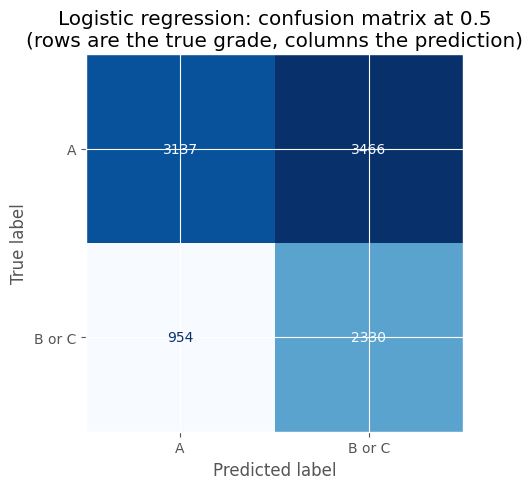

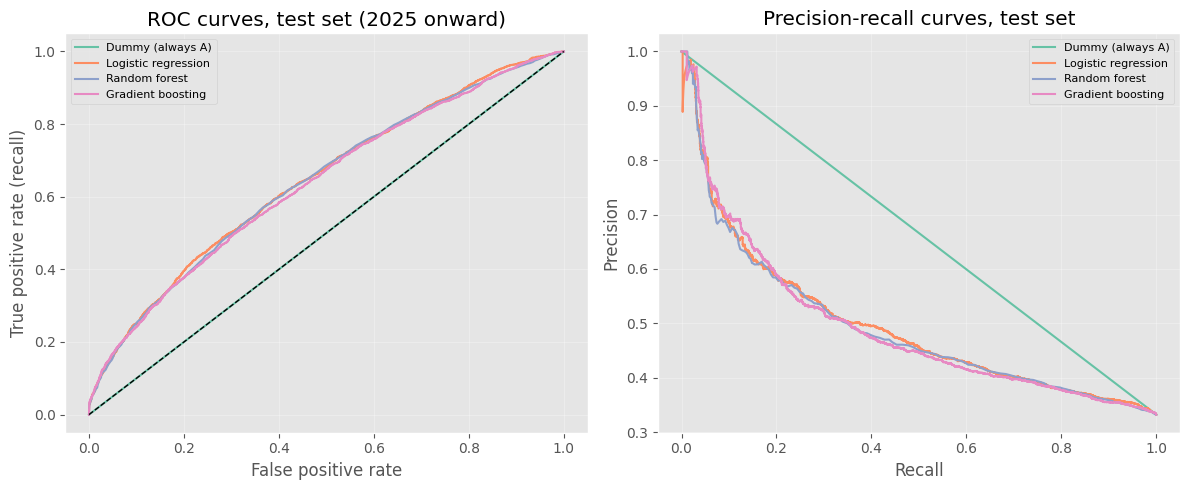

In [127]:
# The best model by test ROC-AUC gets the full look: its confusion
# matrix at the default 0.5 threshold, the ROC and precision-recall
# curves for every model, and a threshold table. The threshold is a
# real decision here, not a default: for the Health Department a missed
# B or C (a bad inspection scored as safe) costs more than a false
# alarm, so we also find the highest threshold that still catches at
# least 80% of the B or C inspections.

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.metrics import precision_recall_curve, roc_curve

best_name = comparison.loc[0, "model"]
best = results[best_name]
p_best = best["p_test"]
print(f"Best model by test ROC-AUC: {best_name}")

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, (p_best >= 0.5).astype(int)),
    display_labels=["A", "B or C"]).plot(ax=ax, cmap="Blues",
                                        colorbar=False)
ax.set_title(f"{best_name}: confusion matrix at 0.5\n"
             "(rows are the true grade, columns the prediction)")
fig.tight_layout()
fig.savefig("pred_confusion.png", dpi=150)
print("Saved pred_confusion.png")
fig

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, res in results.items():
    fpr, tpr, _ = roc_curve(y_test, res["p_test"])
    axes[0].plot(fpr, tpr, label=name)
    prec, rec, _ = precision_recall_curve(y_test, res["p_test"])
    axes[1].plot(rec, prec, label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curves, test set (2025 onward)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curves, test set")
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("pred_curves.png", dpi=150)
print("Saved pred_curves.png")
fig

thresh_rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (p_best >= t).astype(int)
    p = precision_score(y_test, pred, zero_division=0)
    r = recall_score(y_test, pred, zero_division=0)
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    thresh_rows.append({"threshold": t, "precision": p, "recall": r,
                        "F1": f1})
thresh_table = pd.DataFrame(thresh_rows)
print(f"\n{best_name}: trading precision for recall")
print(thresh_table.round(3).to_string(index=False))

scan = np.arange(0.05, 0.96, 0.01)
recalls = [recall_score(y_test, (p_best >= t).astype(int)) for t in scan]
ok = [t for t, r in zip(scan, recalls) if r >= 0.80]
if ok:
    chosen_threshold = float(max(ok))
    pred_c = (p_best >= chosen_threshold).astype(int)
    print(f"\nHighest threshold still catching at least 80% of B or C: "
          f"{chosen_threshold:.2f} (recall "
          f"{recall_score(y_test, pred_c):.3f}, precision "
          f"{precision_score(y_test, pred_c, zero_division=0):.3f})")
else:
    chosen_threshold = 0.5
    print("\nNo scanned threshold reached 80% recall; keeping 0.5.")


### 14.6 What the model leans on

*What this part means:* two views of the same question. Permutation
importance shuffles one feature at a time on the test set and measures
how much accuracy the model loses. Cuisine is the single biggest lever
(drop of 0.046 in ROC-AUC), and the history features come next: prior
mean score (0.023) and prior B or C share (0.013) together roughly match
cuisine, with the last score adding a little more. Geography, after all
the map work, adds almost nothing once cuisine and history are in. The
logistic coefficients tell the readable version of the story. Reopening
inspections push hardest toward B or C (cycle reopening +1.69,
pre-permit reopening +1.36), which makes sense once you know a reopening
only happens after a closure. Indian, Asian, Thai, and Chinese cuisines
push toward B or C; Donuts and Hamburgers push toward A, matching the
cuisine medians back in Section 9. And cycle re-inspections push toward
A once history is held equal: by the second visit, the places that were
going to fail have mostly been separated out, and the ones being
re-checked have usually fixed what was wrong.


Logistic regression, strongest pushes toward B or C:
                                                             feature  coefficient
        cat__inspection_type_Cycle Inspection / Reopening Inspection        1.693
cat__inspection_type_Pre-permit (Operational) / Reopening Inspection        1.360
                                         cat__cuisine_grouped_Indian        0.820
                             cat__cuisine_grouped_Asian/Asian Fusion        0.640
                                           cat__cuisine_grouped_Thai        0.537
                                        cat__cuisine_grouped_Chinese        0.462
   cat__inspection_type_Administrative Miscellaneous / Re-inspection        0.456
                                       cat__cuisine_grouped_Japanese        0.456
                                      cat__cuisine_grouped_Caribbean        0.330
                                 cat__cuisine_grouped_Latin American        0.305

Logistic regression, strongest pushes toward

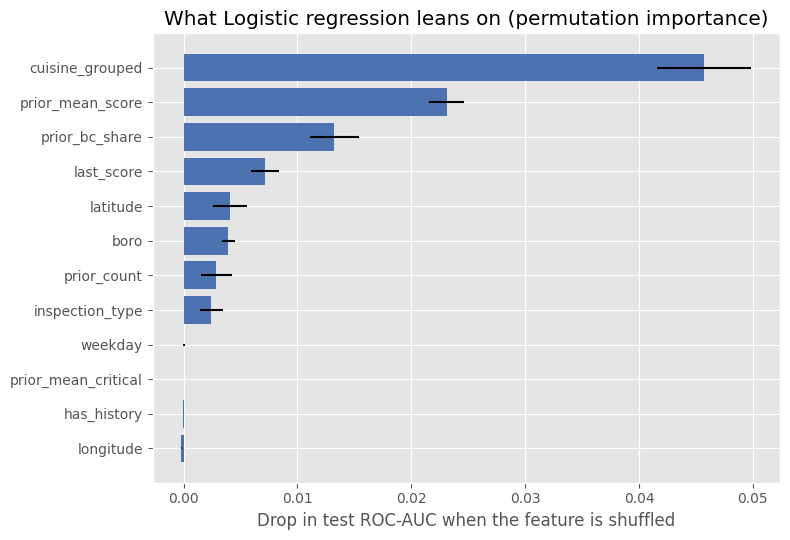

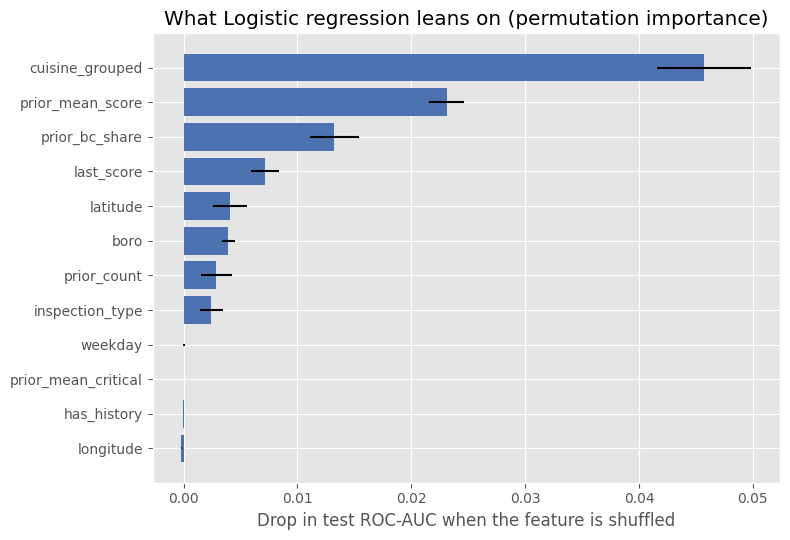

In [128]:
# Two different views. The logistic regression coefficients say which
# features push toward B or C and which push toward A, in a model simple
# enough to read directly. The permutation importance asks the best
# model a blunter question: shuffle one feature at a time on the test
# set and watch how much the ROC-AUC drops. A feature the model truly
# needs costs it accuracy when it is scrambled.

lr_pipe = results["Logistic regression"]["pipe"]
feat_names = lr_pipe.named_steps["pre"].get_feature_names_out()
coefs = lr_pipe.named_steps["model"].coef_[0]
coef_table = (pd.DataFrame({"feature": feat_names, "coefficient": coefs})
              .sort_values("coefficient", ascending=False))
print("Logistic regression, strongest pushes toward B or C:")
print(coef_table.head(10).round(3).to_string(index=False))
print("\nLogistic regression, strongest pushes toward A:")
print(coef_table.tail(10).round(3).to_string(index=False))

from sklearn.inspection import permutation_importance

perm = permutation_importance(best["pipe"], X_test, y_test,
                              n_repeats=5, random_state=42,
                              scoring="roc_auc")
perm_table = (pd.DataFrame({"feature": FEATURES,
                            "AUC drop when shuffled": perm.importances_mean,
                            "std": perm.importances_std})
              .sort_values("AUC drop when shuffled", ascending=False)
              .reset_index(drop=True))
print(f"\nPermutation importance, {best_name}, test set:")
print(perm_table.round(4).to_string(index=False))

top12 = perm_table.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top12["feature"], top12["AUC drop when shuffled"],
        xerr=top12["std"], color="#4C72B0")
ax.set_xlabel("Drop in test ROC-AUC when the feature is shuffled")
ax.set_title(f"What {best_name} leans on (permutation importance)")
fig.tight_layout()
fig.savefig("pred_importance.png", dpi=150)
print("Saved pred_importance.png")
fig


### 14.7 The prediction story in one block

*What this part means:* the summary a slide is built from, printed from
the fitted models rather than typed from memory: the winning model, its
test scores, how it behaves at the chosen threshold, and the three
features it leans on hardest.


In [129]:
# Everything a slide needs, printed from the fitted models rather than
# typed from memory: which model won, how it did on inspections it had
# never seen, how it behaves at the operating threshold chosen in D5,
# and the three features it leans on hardest.

best_row = comparison[comparison["model"] == best_name].iloc[0]
pred_chosen = (p_best >= chosen_threshold).astype(int)
top3 = perm_table["feature"].head(3).tolist()

print("=" * 64)
print("PREDICTION SUMMARY")
print("=" * 64)
print(f"Question: will this inspection end in a B or C grade?")
print(f"Learned from {len(X_train):,} inspections up to the end of 2024,")
print(f"tested on {len(X_test):,} inspections from 2025 onward.")
print(f"Best model: {best_name}")
print(f"  test ROC-AUC {best_row['test ROC-AUC']:.3f}, "
      f"test PR-AUC {best_row['test PR-AUC']:.3f}")
print(f"  at threshold {chosen_threshold:.2f}: recall "
      f"{recall_score(y_test, pred_chosen):.3f}, precision "
      f"{precision_score(y_test, pred_chosen, zero_division=0):.3f}")
print(f"Features it leans on most: {', '.join(top3)}")
print("=" * 64)


PREDICTION SUMMARY
Question: will this inspection end in a B or C grade?
Learned from 9,111 inspections up to the end of 2024,
tested on 9,887 inspections from 2025 onward.
Best model: Logistic regression
  test ROC-AUC 0.644, test PR-AUC 0.496
  at threshold 0.45: recall 0.822, precision 0.376
Features it leans on most: cuisine_grouped, prior_mean_score, prior_bc_share


### 14.8 Dimensionality check: PCA on the numeric features

*What this part means:* principal component analysis asks whether the
eleven numeric features are mostly saying the same thing in different
units. If they were, a few combined components would carry nearly all
of the variance, and the model could use those instead. They are not.
The first component explains 21.8% of the variance and the second
16.6%, and it takes 7 of the 11 components to reach 80% and 8 to reach
90%. The components do read clearly: the first is a past-performance
axis (prior mean score, last score, and prior critical violations load
on it together), and the second is a history-depth axis (how many prior
inspections exist, and how checkered they were). How a restaurant did
and how much record it has are two different things, and the data keeps
them separate. As a final check, logistic regression trained on the
component scores reaches a test ROC-AUC of 0.620 using all components
and 0.631 using the 90% set, against 0.644 for the full model on the
original features (which also includes the categorical ones). So the
model keeps the original features: they predict at least as well and
can be explained in plain words, which components cannot. The scatter
of the first two components, colored by outcome, shows the same story
the AUC tells: the classes overlap heavily, and no rotation of these
features was going to separate them cleanly.


Using X_train and X_test from cell D3

Explained variance per component:
component  variance %  cumulative %
      PC1        21.8          21.8
      PC2        16.6          38.5
      PC3        12.8          51.2
      PC4        10.4          61.6
      PC5         9.3          70.9
      PC6         8.5          79.4
      PC7         7.6          87.0
      PC8         5.4          92.5
      PC9         4.4          96.9
     PC10         2.3          99.2
     PC11         0.8         100.0

Components needed for 80% of variance: 7 of 11
Components needed for 90% of variance: 8 of 11

PC1 loadings, strongest first:
prior_mean_score       0.61
last_score             0.60
prior_mean_critical    0.46
has_history            0.14
days_since_prior      -0.14
month                  0.09
prior_count            0.08
prior_bc_share         0.06
latitude              -0.03
longitude              0.02
weekday               -0.01

PC2 loadings, strongest first:
prior_count            0.66


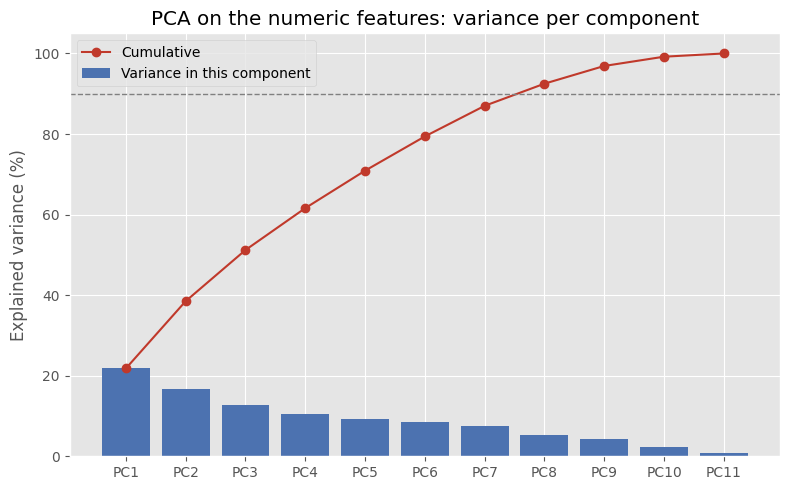

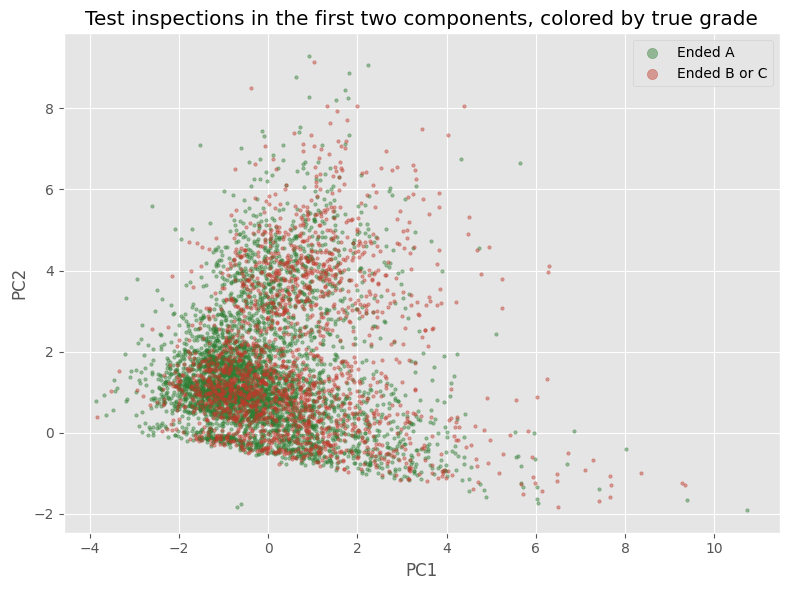

In [130]:
# A fair question after all that feature building: are the numeric
# features mostly saying the same thing in different words? PCA answers
# it. It rotates the scaled numeric features into components that are
# uncorrelated with each other, ordered by how much of the total variance
# each one carries. If two or three components carried almost everything,
# the rest of the features would be near copies and could be dropped.
# If the variance spreads out, each feature is bringing its own piece.
#
# This cell is a diagnostic, not a modeling step. The final model keeps
# the original features, because "prior mean score" can be explained to
# a restaurant owner and "principal component 2" cannot. But the check
# costs nothing and it closes the dimensionality question with evidence.

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

try:
    # in the notebook, D3 and D4 already built these
    Xtr_num = X_train[NUM_COLS]
    Xte_num = X_test[NUM_COLS]
    y_tr, y_te = y_train, y_test
    print("Using X_train and X_test from cell D3")
except NameError:
    NUM_COLS = ["latitude", "longitude", "month", "weekday",
                "prior_count", "prior_mean_score", "prior_bc_share",
                "prior_mean_critical", "days_since_prior", "last_score",
                "has_history"]
    table = pd.read_csv("modeling_table.csv")
    Xtr_num = table.loc[table["split"] == "train", NUM_COLS]
    Xte_num = table.loc[table["split"] == "test", NUM_COLS]
    y_tr = table.loc[table["split"] == "train", "y"]
    y_te = table.loc[table["split"] == "test", "y"]
    print("Loaded modeling_table.csv")

# PCA compares raw numbers across features, so the scaling step is not
# optional dressing: days_since_prior runs into the thousands while
# prior_bc_share sits between 0 and 1, and unscaled the days column
# would swallow the whole analysis. Impute the median first, scale,
# and fit both on the training rows only.
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
Xtr_scaled = scaler.fit_transform(imputer.fit_transform(Xtr_num))
Xte_scaled = scaler.transform(imputer.transform(Xte_num))

pca = PCA().fit(Xtr_scaled)
explained = 100 * pca.explained_variance_ratio_
var_table = pd.DataFrame({"component": [f"PC{i}" for i in range(1, len(explained) + 1)],
                          "variance %": np.round(explained, 1),
                          "cumulative %": np.round(np.cumsum(explained), 1)})
print("\nExplained variance per component:")
print(var_table.to_string(index=False))

n80 = int(np.argmax(np.cumsum(explained) >= 80) + 1)
n90 = int(np.argmax(np.cumsum(explained) >= 90) + 1)
print(f"\nComponents needed for 80% of variance: {n80} of {len(explained)}")
print(f"Components needed for 90% of variance: {n90} of {len(explained)}")

# What each of the first two components is actually made of.
loadings = pd.DataFrame(pca.components_.T, index=NUM_COLS,
                        columns=[f"PC{i}" for i in range(1, len(explained) + 1)])
for pc in ["PC1", "PC2"]:
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index)
    print(f"\n{pc} loadings, strongest first:")
    print(top.round(2).to_string())

# Figure 1: the variance picture, bars per component and the running total.
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(var_table["component"], var_table["variance %"], color="#4C72B0",
       label="Variance in this component")
ax.plot(var_table["component"], var_table["cumulative %"], color="#C0392B",
        marker="o", label="Cumulative")
ax.axhline(90, color="grey", ls="--", lw=1)
ax.set_ylabel("Explained variance (%)")
ax.set_title("PCA on the numeric features: variance per component")
ax.legend()
fig.tight_layout()
fig.savefig("pca_variance.png", dpi=150)
print("\nSaved pca_variance.png")
fig

# Figure 2: the test set in the PC1 and PC2 plane, colored by outcome.
# If the classes separated cleanly down here, two components would be
# nearly enough to predict with. A heavy overlap is itself the finding.
pca2 = PCA(n_components=2).fit(Xtr_scaled)
test_scores = pca2.transform(Xte_scaled)
sample = pd.DataFrame({"PC1": test_scores[:, 0], "PC2": test_scores[:, 1],
                       "y": np.asarray(y_te)}).sample(n=min(6000, len(test_scores)),
                                                      random_state=42)
fig, ax = plt.subplots(figsize=(8, 6))
for label, color, name in [(0, "#2E7D32", "Ended A"), (1, "#C0392B", "Ended B or C")]:
    part = sample[sample["y"] == label]
    ax.scatter(part["PC1"], part["PC2"], s=6, alpha=0.45, c=color, label=name)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Test inspections in the first two components, colored by true grade")
ax.legend(markerscale=3)
fig.tight_layout()
fig.savefig("pca_scatter.png", dpi=150)
print("Saved pca_scatter.png")
fig

# The honesty check: give logistic regression the components instead of
# the original features and compare test ROC-AUC with 0.644, the score
# the plain features earned in D4. All components first, then only the
# set that reaches 90% of variance.
def lr_on_pcs(n_components):
    p = PCA(n_components=n_components).fit(Xtr_scaled)
    model = LogisticRegression(max_iter=1000, class_weight="balanced",
                               random_state=42)
    model.fit(p.transform(Xtr_scaled), y_tr)
    return roc_auc_score(y_te, model.predict_proba(p.transform(Xte_scaled))[:, 1])

auc_all = lr_on_pcs(len(NUM_COLS))
auc_90 = lr_on_pcs(n90)
print(f"\nLogistic regression on all {len(NUM_COLS)} components: test ROC-AUC {auc_all:.3f}")
print(f"Logistic regression on the {n90} components reaching 90%: test ROC-AUC {auc_90:.3f}")
print("Same model on the original numeric features: test ROC-AUC 0.644")

print(f"\nDimensionality check in one line: the variance is spread across "
      f"{n90} of {len(NUM_COLS)} components for 90%, so the numeric features "
      f"are not redundant copies, and logistic regression on the components "
      f"({auc_90:.3f}) does not beat the original features (0.644).")


### What the prediction work means, and its limits

Three honest conclusions. First, the signal is real but modest: cuisine
and the restaurant's own history, known before anyone walks in, rank
inspection risk clearly better than chance and better than any single
rule we tested, and the simplest model beat the flexible ones because
the flexible ones memorized the training years. Second, the model is a
prioritization tool, not a judge. At the recall-first threshold it flags
a wide net, most of which still ends in an A, so its honest use is
ordering a visit list and deciding where follow-up capacity goes first,
the same reading the hero map gave in Section 13. Using it to label a
restaurant in advance would be exactly the mistake the dummy model
warns about: a number that looks decisive and is not. Third, the target
itself has a shape worth remembering: because grades settle at
re-inspection, this model predicts settled outcomes, and a version aimed
at first visits would need the score-based target (14 or more points)
that Section 13.5 used instead. Natural next steps, in order: richer
history (violation types in the prior visits, not just counts and
scores), a per-inspection-type model, and a calibration check so the
probabilities can be read as probabilities. The midterm deliverable ends
here: a notebook that loads the raw city file, explains it, maps it,
and predicts with it, with every step's limits stated where the step
happens.
